# Import Required Modules

In [1]:
import pandas as pd
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings('ignore')
from matplotlib.lines import Line2D
import glob
from google.colab import drive

In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:

BASE_DIR = Path('/content/drive/MyDrive/MSc-research-code/')
EVAL_DIR = BASE_DIR / 'evaluation_results'
EVAL_OUT_DIR = EVAL_DIR / 'final_plots'

EVAL_OUT_DIR.mkdir(parents=True, exist_ok=True)



# Load Shap Importance File in Each model and Combine in to One

In [4]:


# File mapping
SHAP_FILES = {
    # LightGBM
    ('LightGBM', 'Sub-SST'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lightgbm/lightbgm_sst_subsurface_combined/lgbm_sst_subsurface_combined_shap_importance.csv',
    ('LightGBM', '0-50m'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lightgbm/lightbgm_subsurface_layer_0-50m_layer/lgbm_subsurface_layer_0-50m_layer_shap_importance.csv',
    ('LightGBM', '50-100m'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lightgbm/lightbgm_subsurface_layer_50-100m_layer/lgbm_subsurface_layer_50-100m_layer_shap_importance.csv',
    ('LightGBM', '100-150m'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lightgbm/lightbgm_subsurface_layer_100-150m_layer/lgbm_subsurface_layer_100-150m_layer_shap_importance.csv',
    # LSTM
    ('LSTM', 'Sub-SST'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lstm/lstm_sst_subsurface_combined/lstm_sst_subsurface_combined_shap_importance.csv',
    ('LSTM', '0-50m'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lstm/lstm_subsurface_layer_0-50m_layer/lstm_subsurface_layer_0-50m_layer_shap_importance.csv',
    ('LSTM', '50-100m'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lstm/lstm_subsurface_layer_50-100m_layer/lstm_subsurface_layer_50-100m_layer_shap_importance.csv',
    ('LSTM', '100-150m'):
        '/content/drive/MyDrive/MSc-research-code/trained_models/lstm/lstm_subsurface_layer_100-150m_layer/lstm_subsurface_layer_100-150m_layer_shap_importance.csv',
}

# Load and combine
dfs = []
for (model, config), path in SHAP_FILES.items():
    try:
        df = pd.read_csv(path)
        df['model']  = model
        df['config'] = config
        dfs.append(df)
        print(f'Loaded: {model} | {config} | shape={df.shape}')
    except FileNotFoundError:
        print(f'Not found: {model} | {config}')

shap_combined = pd.concat(dfs, ignore_index=True)

#  Check structure
print(f'\nCombined shape: {shap_combined.shape}')
print(f'Columns: {shap_combined.columns.tolist()}')
print(f'\nFirst 3 rows:')
print(shap_combined.head(3).to_string())

#Save
OUTPUT_DIR = Path('/content/drive/MyDrive/MSc-research-code/evaluation_results/')
shap_combined.to_csv(
    OUTPUT_DIR / 'shap_combined.csv',
    index=False
)
print(f'\nSaved: shap_combined.csv')
print(f'Models:  {shap_combined["model"].unique()}')
print(f'Configs: {shap_combined["config"].unique()}')

Loaded: LightGBM | Sub-SST | shape=(66, 7)
Loaded: LightGBM | 0-50m | shape=(66, 7)
Loaded: LightGBM | 50-100m | shape=(66, 7)
Loaded: LightGBM | 100-150m | shape=(66, 7)
Loaded: LSTM | Sub-SST | shape=(66, 7)
Loaded: LSTM | 0-50m | shape=(66, 7)
Loaded: LSTM | 50-100m | shape=(66, 7)
Loaded: LSTM | 100-150m | shape=(66, 7)

Combined shape: (528, 7)
Columns: ['config', 'target', 'lead_time', 'feature', 'shap_importance', 'rank', 'model']

First 3 rows:
    config   target  lead_time   feature  shap_importance  rank     model
0  Sub-SST  mhw_sst          3       sst        32.239912     1  LightGBM
1  Sub-SST  mhw_sst          3  ssr_flux        20.451961     2  LightGBM
2  Sub-SST  mhw_sst          3       t2m         9.447059     3  LightGBM

Saved: shap_combined.csv
Models:  ['LightGBM' 'LSTM']
Configs: ['Sub-SST' '0-50m' '50-100m' '100-150m']


# Load Evaluation Metrics CSV and Shap Importance CSV

In [5]:


# Load data
BASE = '/content/drive/MyDrive/MSc-research-code/'
eval_df = pd.read_csv(BASE + 'evaluation_results/all_evaluation_results.csv')
shap_df = pd.read_csv(BASE + 'evaluation_results/shap_combined.csv')

# Constants
CONFIGS    = ['Sub-SST', '0-50m', '50-100m', '100-150m']
MODELS     = ['LightGBM', 'LSTM']
LEAD_TIMES = [3, 5, 7, 9, 12, 14]

CONFIG_LABELS = {
    'Sub-SST':   'Sub-SST',
    '0-50m':     '0-50 m',
    '50-100m':   '50-100 m',
    '100-150m':  '100-150 m',
}
FEATURE_LABELS = {
    'sst':          'SST',
    'temp_0_50m':   'Temp 0-50m',
    'temp_50_100m': 'Temp 50-100m',
    'temp_100_150m':'Temp 100-150m',
    'ssr_flux':     'SW Radiation',
    'str_flux':     'LW Radiation',
    'latent_flux':  'Latent Heat',
    'sensible_flux':'Sensible Heat',
    't2m':          '2m Air Temp',
    'msl':          'Sea Level Pressure',
    'wind_speed':   'Wind Speed',
}
C = {
    'Sub-SST':   '#1565C0',
    '0-50m':     '#2E7D32',
    '50-100m':   '#E65100',
    '100-150m':  '#6A1B9A',
    'LightGBM':  '#1565C0',
    'LSTM':      '#C62828',
}

metrics_compare = [
    ('auc',      'ROC-AUC',               0.5, 'min', 0.2,   1.0),
    ('bss',      'BSS',               0.0,  'min',-0.1,  0.65),
    ('brier',    'Brier Score',       0.25, 'max', 0.0,  0.5),
    ('sedi',     'SEDI',              0.0,  'min',-0.1,  0.9),
    # ('tpr',      'TPR (Hit Rate)',    0.5,  'min', 0.0,  1.0),
    # ('fpr_tpr_ratio',      'FPR/TPR Ratio', 0.0,  'max', 1.0,  1.0)
    ('fpr_tpr_ratio', 'FPR/TPR Ratio', 1.0, 'max', 0.0, 1.0)
    # ('tnr',      'TNR (Specificity)', 0.5,  'min', 0.0,  1.0),
]


In [6]:

print(eval_df.head(3))
print(eval_df.columns.tolist())

      model   config   target  lead_time calibration  calibrated  \
0  LightGBM  Sub-SST  mhw_sst          3        none       False   
1  LightGBM  Sub-SST  mhw_sst          3        none       False   
2  LightGBM  Sub-SST  mhw_sst          3        Beta        True   

  threshold_strategy  best_threshold  best_epoch  best_val_auc  ...  \
0             mhw_f1            0.30      2638.0           NaN  ...   
1           macro_f1            0.40      2638.0           NaN  ...   
2             mhw_f1            0.43      2638.0           NaN  ...   

   prob_pct10  prob_pct90   n_test  n_pos_test  n_neg_test  mhw_rate_test  \
0    0.045368    0.802075  1037028      586007      451021       0.565083   
1    0.045368    0.802075  1037028      586007      451021       0.565083   
2    0.122778    0.884074  1037028      586007      451021       0.565083   

   brier_thr   ece_thr  n_onset  onset_tpr  
0   0.135756  0.055521    48641   0.434222  
1   0.135756  0.055521    48641   0.313336 

In [7]:

print(shap_df.head(3))
print(shap_df.columns.tolist())

    config   target  lead_time   feature  shap_importance  rank     model
0  Sub-SST  mhw_sst          3       sst        32.239912     1  LightGBM
1  Sub-SST  mhw_sst          3  ssr_flux        20.451961     2  LightGBM
2  Sub-SST  mhw_sst          3       t2m         9.447059     3  LightGBM
['config', 'target', 'lead_time', 'feature', 'shap_importance', 'rank', 'model']


# Creating Dataframe for Plot Generation

In [11]:
#  Best calibration — variant chosen on the THRESHOLD-TUNING split (no test data).
#  Brier and ECE do not depend on the threshold, so the same variant is chosen
#  for both threshold strategies. Test metrics are only read for that variant.
assert {'brier_thr', 'ece_thr'} <= set(eval_df.columns), \
    'use all_evaluation_results.csv from the v5 run'

def select_on_thr(grp):
    grp = grp.copy()
    grp['brier_rank'] = grp['brier_thr'].rank()
    grp['ece_rank']   = grp['ece_thr'].rank()
    grp['combined']   = grp['brier_rank'] + grp['ece_rank']
    # Tie -> first row in the order none, Beta/TempScale, +SLD (the simpler
    # variant), exactly as in the v5 evaluation that produced best_per_model.csv
    return grp.loc[grp['combined'].idxmin()]

#  MHW-F1 only (missing an MHW costs more than a false alarm)
mhw = eval_df[eval_df['threshold_strategy'] == 'mhw_f1']
best_df = pd.DataFrame([
    select_on_thr(grp)
    for _, grp in mhw.groupby(['model', 'config', 'lead_time'])
]).reset_index(drop=True)

#  Both strategies: take the THR-chosen variant, then its row per strategy
key = ['model', 'config', 'lead_time', 'calibration']
both_df = (eval_df[eval_df['threshold_strategy'].isin(['mhw_f1', 'macro_f1'])]
           .merge(best_df[key], on=key, how='inner')
           .reset_index(drop=True))

#  Consistency check against the paper's Table II
ref = pd.read_csv(OUTPUT_DIR / 'best_per_model.csv')
chk = best_df[key].merge(ref[key], on=key)
assert len(chk) == len(best_df) == 48, f'{len(chk)}/48 match best_per_model.csv'
print('Selection matches best_per_model.csv: 48/48')

Selection matches best_per_model.csv: 48/48


In [12]:

# Compute ratios
both_df['fpr_tpr_ratio'] = (
    both_df['fpr'] /
    both_df['tpr'].replace(0, np.nan)
)
both_df['fnr_tnr_ratio'] = (
    both_df['fnr'] /
    both_df['tnr'].replace(0, np.nan)
)

best_df['fpr_tpr_ratio'] = (
    best_df['fpr'] /
    best_df['tpr'].replace(0, np.nan)
)

# Thresold Comparison Plot

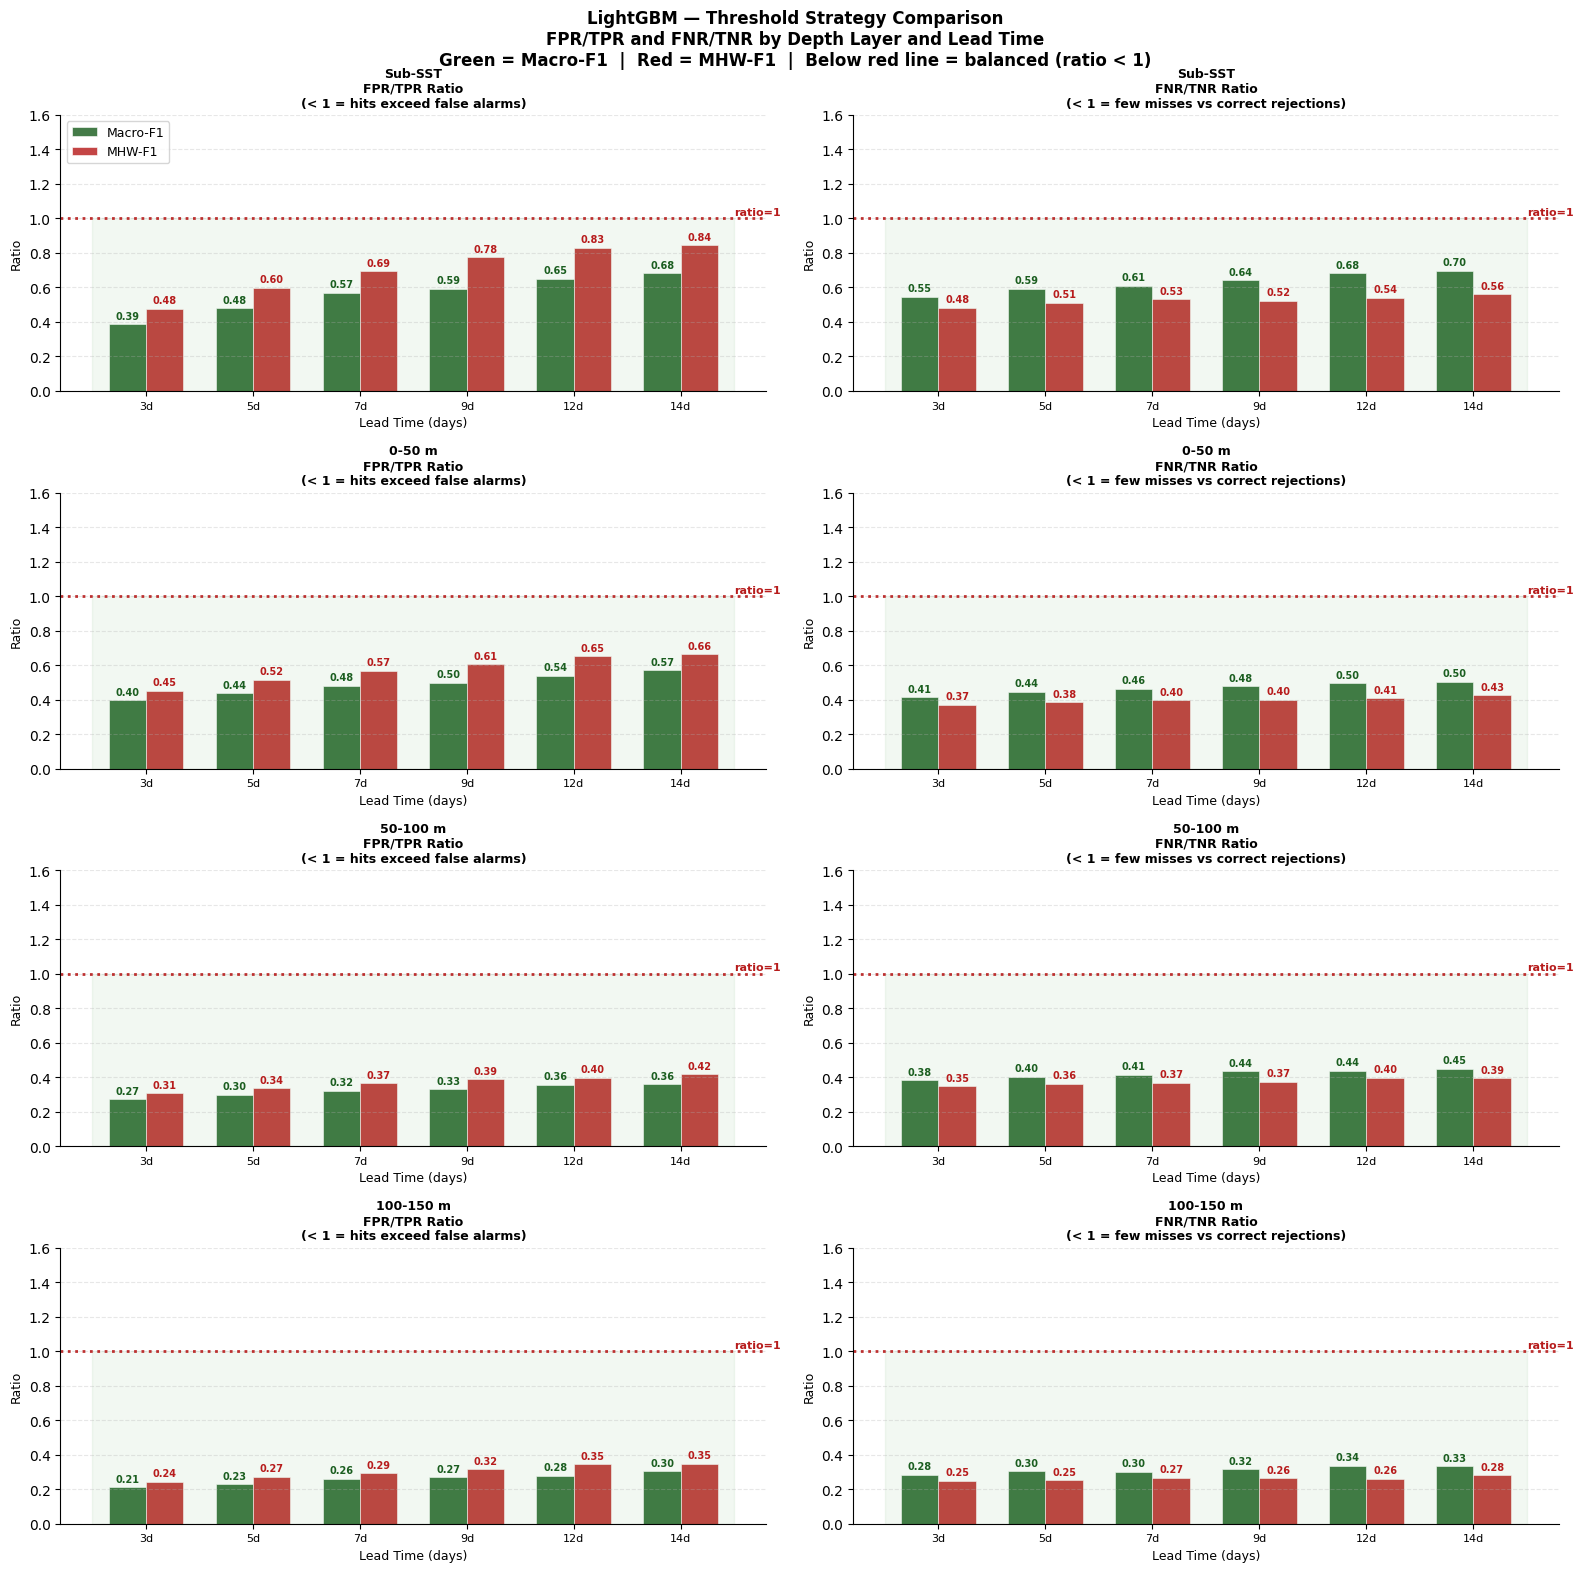

Saved: plot0_threshold_bars_lightgbm.png


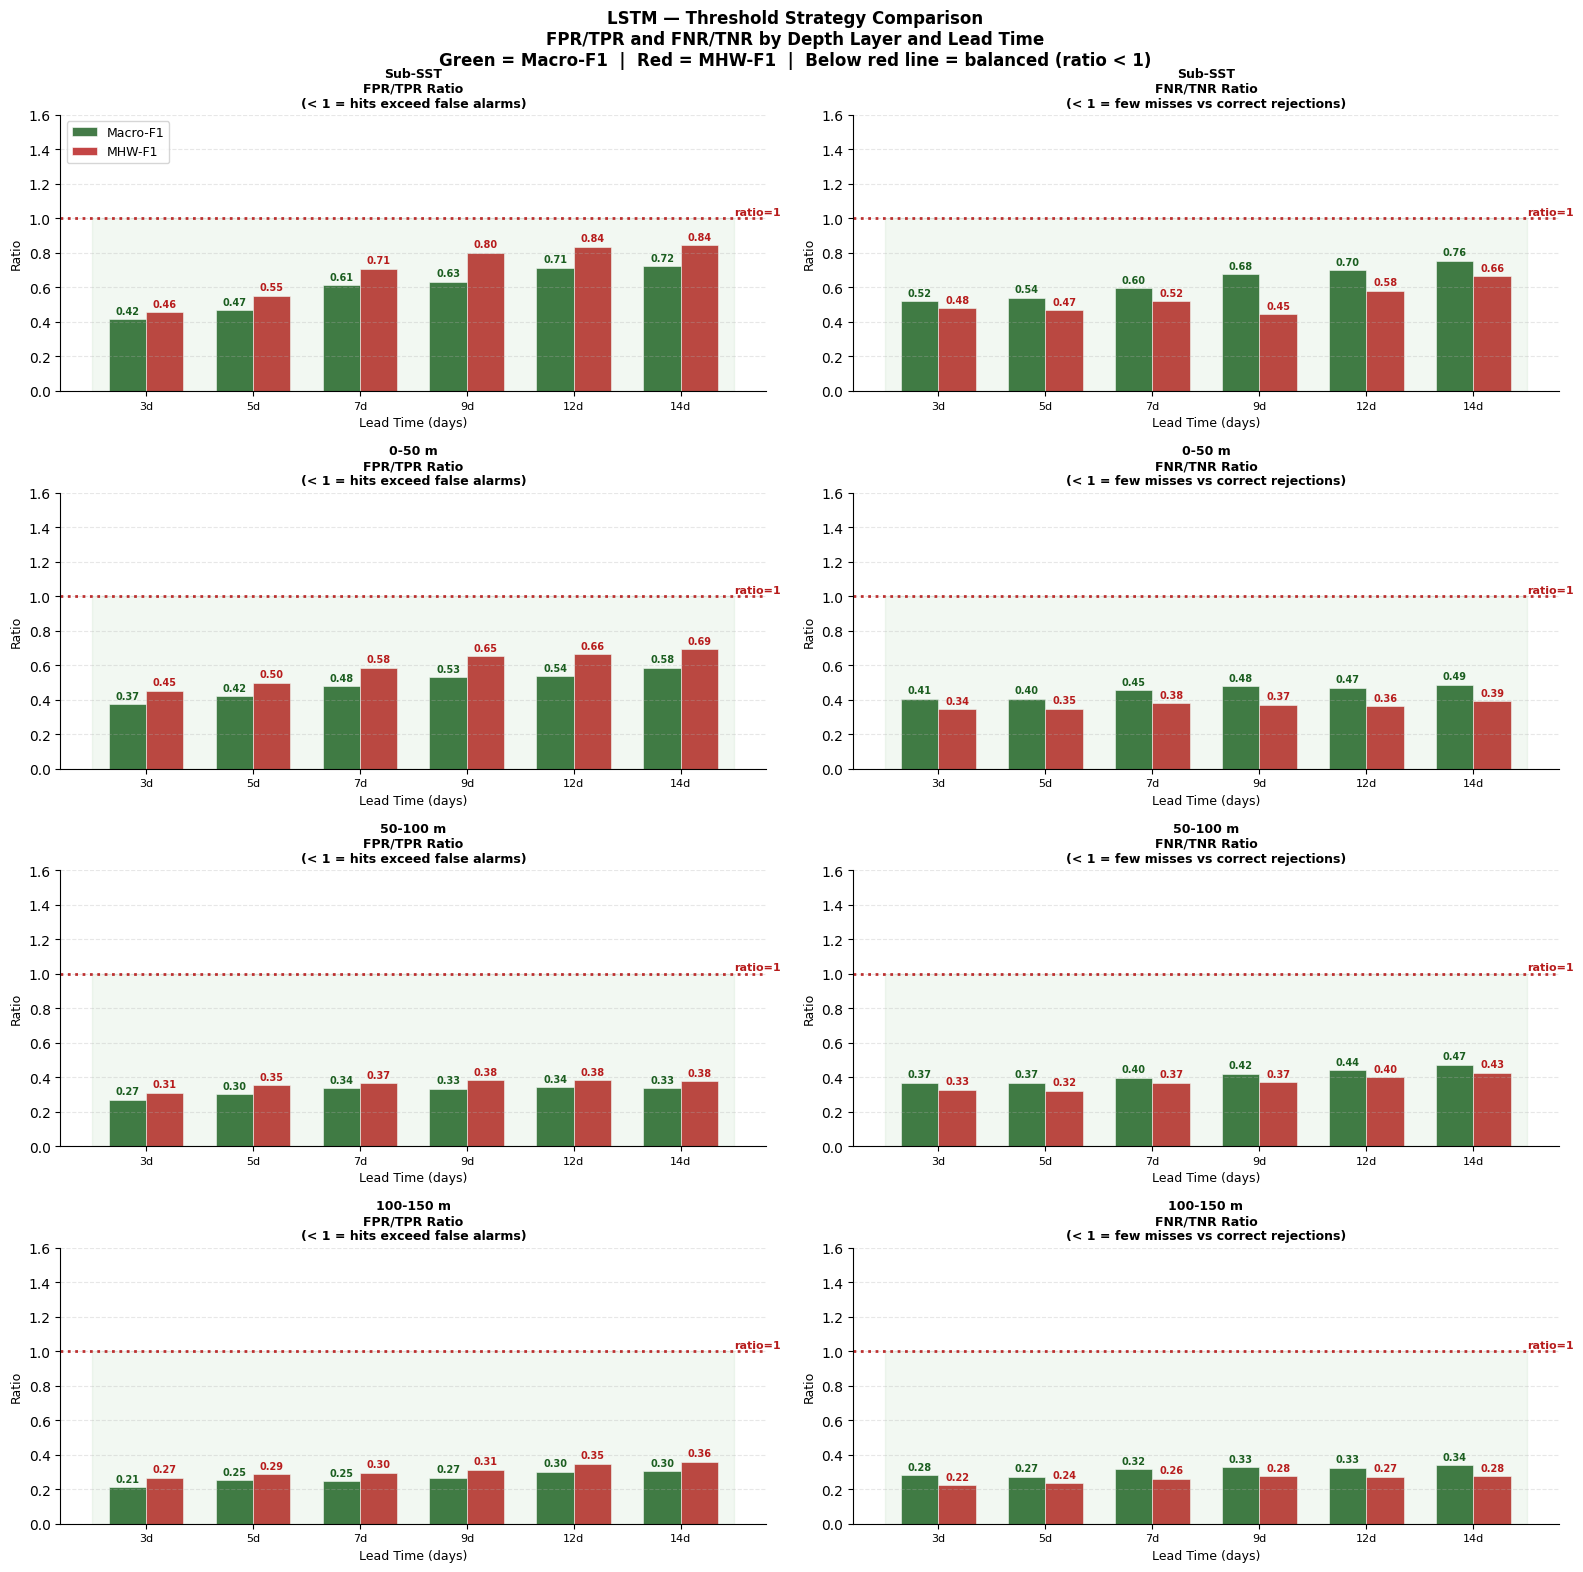

Saved: plot0_threshold_bars_lstm.png

RATIO SUMMARY — Macro-F1 vs MHW-F1
FPR/TPR < 1: false alarm rate below hit rate (usefulness criterion)
FNR/TNR: missed-event rate relative to correct-rejection rate (lower = fewer missed MHWs)

LightGBM:
  Config                Lead  MACRO FPR/TPR  MHW FPR/TPR  MACRO FNR/TNR  MHW FNR/TNR
  ---------------------------------------------------------------------------
  Sub-SST                  3d        0.387        0.477         0.546         0.483
  Sub-SST                  5d        0.479        0.597         0.593         0.511
  Sub-SST                  7d        0.569        0.694         0.609         0.530
  Sub-SST                  9d        0.593        0.776         0.640         0.522
  Sub-SST                 12d        0.649        0.829         0.684         0.539
  Sub-SST                 14d        0.683        0.844         0.697         0.561
  0-50 m                   3d        0.395        0.451         0.415         0.371
  0-50 

In [26]:


ratios = [
    ('fpr_tpr_ratio',
     'FPR/TPR Ratio\n(< 1 = hits exceed false alarms)'),
    ('fnr_tnr_ratio',
     'FNR/TNR Ratio\n(< 1 = few misses vs correct rejections)'),
]

x      = np.arange(len(LEAD_TIMES))
width  = 0.35
colors = {
    'macro_f1': '#1B5E20',
    'mhw_f1':   '#B71C1C',
}
labels = {
    'macro_f1': 'Macro-F1',
    'mhw_f1':   'MHW-F1',
}

for model in MODELS:

    fig, axes = plt.subplots(
        len(CONFIGS), 2,
        figsize=(16, 4 * len(CONFIGS))
    )
    fig.suptitle(
        f'{model} — Threshold Strategy Comparison\n'
        f'FPR/TPR and FNR/TNR by Depth Layer and Lead Time\n'
        f'Green = Macro-F1  |  Red = MHW-F1  |  '
        f'Below red line = balanced (ratio < 1)',
        fontsize=12, fontweight='bold'
    )

    for row, config in enumerate(CONFIGS):
        for col, (metric, ylabel) in enumerate(ratios):
            ax = axes[row, col]

            for i, (strategy, offset) in enumerate(zip(
                ['macro_f1', 'mhw_f1'],
                [-width/2,    width/2]
            )):
                sub = both_df[
                    (both_df['model']  == model) &
                    (both_df['config'] == config) &
                    (both_df['threshold_strategy'] == strategy)
                ].sort_values('lead_time')

                vals = sub[metric].values

                bars = ax.bar(
                    x + offset,
                    vals,
                    width,
                    label=labels[strategy],
                    color=colors[strategy],
                    alpha=0.82,
                    edgecolor='white',
                    linewidth=0.5
                )

                # Value labels on bars
                for bar, val in zip(bars, vals):
                    if not np.isnan(val):
                        ax.text(
                            bar.get_x() + bar.get_width()/2,
                            bar.get_height() + 0.02,
                            f'{val:.2f}',
                            ha='center', va='bottom',
                            fontsize=7,
                            color=colors[strategy],
                            fontweight='bold'
                        )

            # Reference line at 1.0
            ax.axhline(
                1.0,
                color='#B71C1C',
                linestyle=':',
                linewidth=2.0,
                alpha=0.9
            )
            ax.text(
                x[-1] + 0.5, 1.02,
                'ratio=1',
                fontsize=8,
                color='#B71C1C',
                fontweight='bold'
            )

            # Shade balanced region
            ax.fill_between(
                [-0.5, len(LEAD_TIMES) - 0.5],
                0, 1.0,
                alpha=0.05,
                color='green'
            )

            # Labels
            ax.set_title(
                f'{CONFIG_LABELS[config]}\n{ylabel}',
                fontsize=9, fontweight='bold'
            )
            ax.set_xlabel(
                'Lead Time (days)', fontsize=9
            )
            ax.set_ylabel('Ratio', fontsize=9)
            ax.set_xticks(x)
            ax.set_xticklabels(
                [f'{l}d' for l in LEAD_TIMES],
                fontsize=8
            )
            ax.set_ylim(0, 1.6)
            ax.grid(
                axis='y', alpha=0.3,
                linestyle='--'
            )
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            # Legend only on first subplot
            if row == 0 and col == 0:
                ax.legend(
                    fontsize=9,
                    loc='upper left'
                )

    plt.tight_layout()
    fname = f'plot0_threshold_bars_{model.lower()}.png'
    plt.savefig(
        EVAL_OUT_DIR / f'{fname}',
        dpi=800, bbox_inches='tight'
    )
    plt.show()
    print(f'Saved: {fname}')

# Summary table
print('\n' + '='*75)
print('RATIO SUMMARY — Macro-F1 vs MHW-F1')
print('FPR/TPR < 1: false alarm rate below hit rate (usefulness criterion)')
print('FNR/TNR: missed-event rate relative to correct-rejection rate (lower = fewer missed MHWs)')
print('='*75)

for model in MODELS:
    print(f'\n{model}:')
    print(
        f'  {"Config":<20} {"Lead":>5} '
        f'{"MACRO FPR/TPR":>14} {"MHW FPR/TPR":>12} '
        f'{"MACRO FNR/TNR":>14} {"MHW FNR/TNR":>12}'
    )
    print(f'  {"-"*75}')

    for config in CONFIGS:
        for lead in LEAD_TIMES:
            macro_row = both_df[
                (both_df['model']  == model) &
                (both_df['config'] == config) &
                (both_df['lead_time'] == lead) &
                (both_df['threshold_strategy'] == 'macro_f1')
            ]
            mhw_row = both_df[
                (both_df['model']  == model) &
                (both_df['config'] == config) &
                (both_df['lead_time'] == lead) &
                (both_df['threshold_strategy'] == 'mhw_f1')
            ]

            if len(macro_row) == 0 or len(mhw_row) == 0:
                continue

            m  = macro_row.iloc[0]
            mh = mhw_row.iloc[0]

            m_r1  = m['fpr_tpr_ratio']
            mh_r1 = mh['fpr_tpr_ratio']
            m_r2  = m['fnr_tnr_ratio']
            mh_r2 = mh['fnr_tnr_ratio']

            # Mark winner


            print(
                f'  {CONFIG_LABELS[config]:<20} '
                f'{lead:>5}d '
                f'{m_r1:>12.3f} '
                f'{mh_r1:>12.3f}  '
                f'{m_r2:>12.3f}  '
                f'{mh_r2:>12.3f}'
            )



### Mean Metric Value Per Config

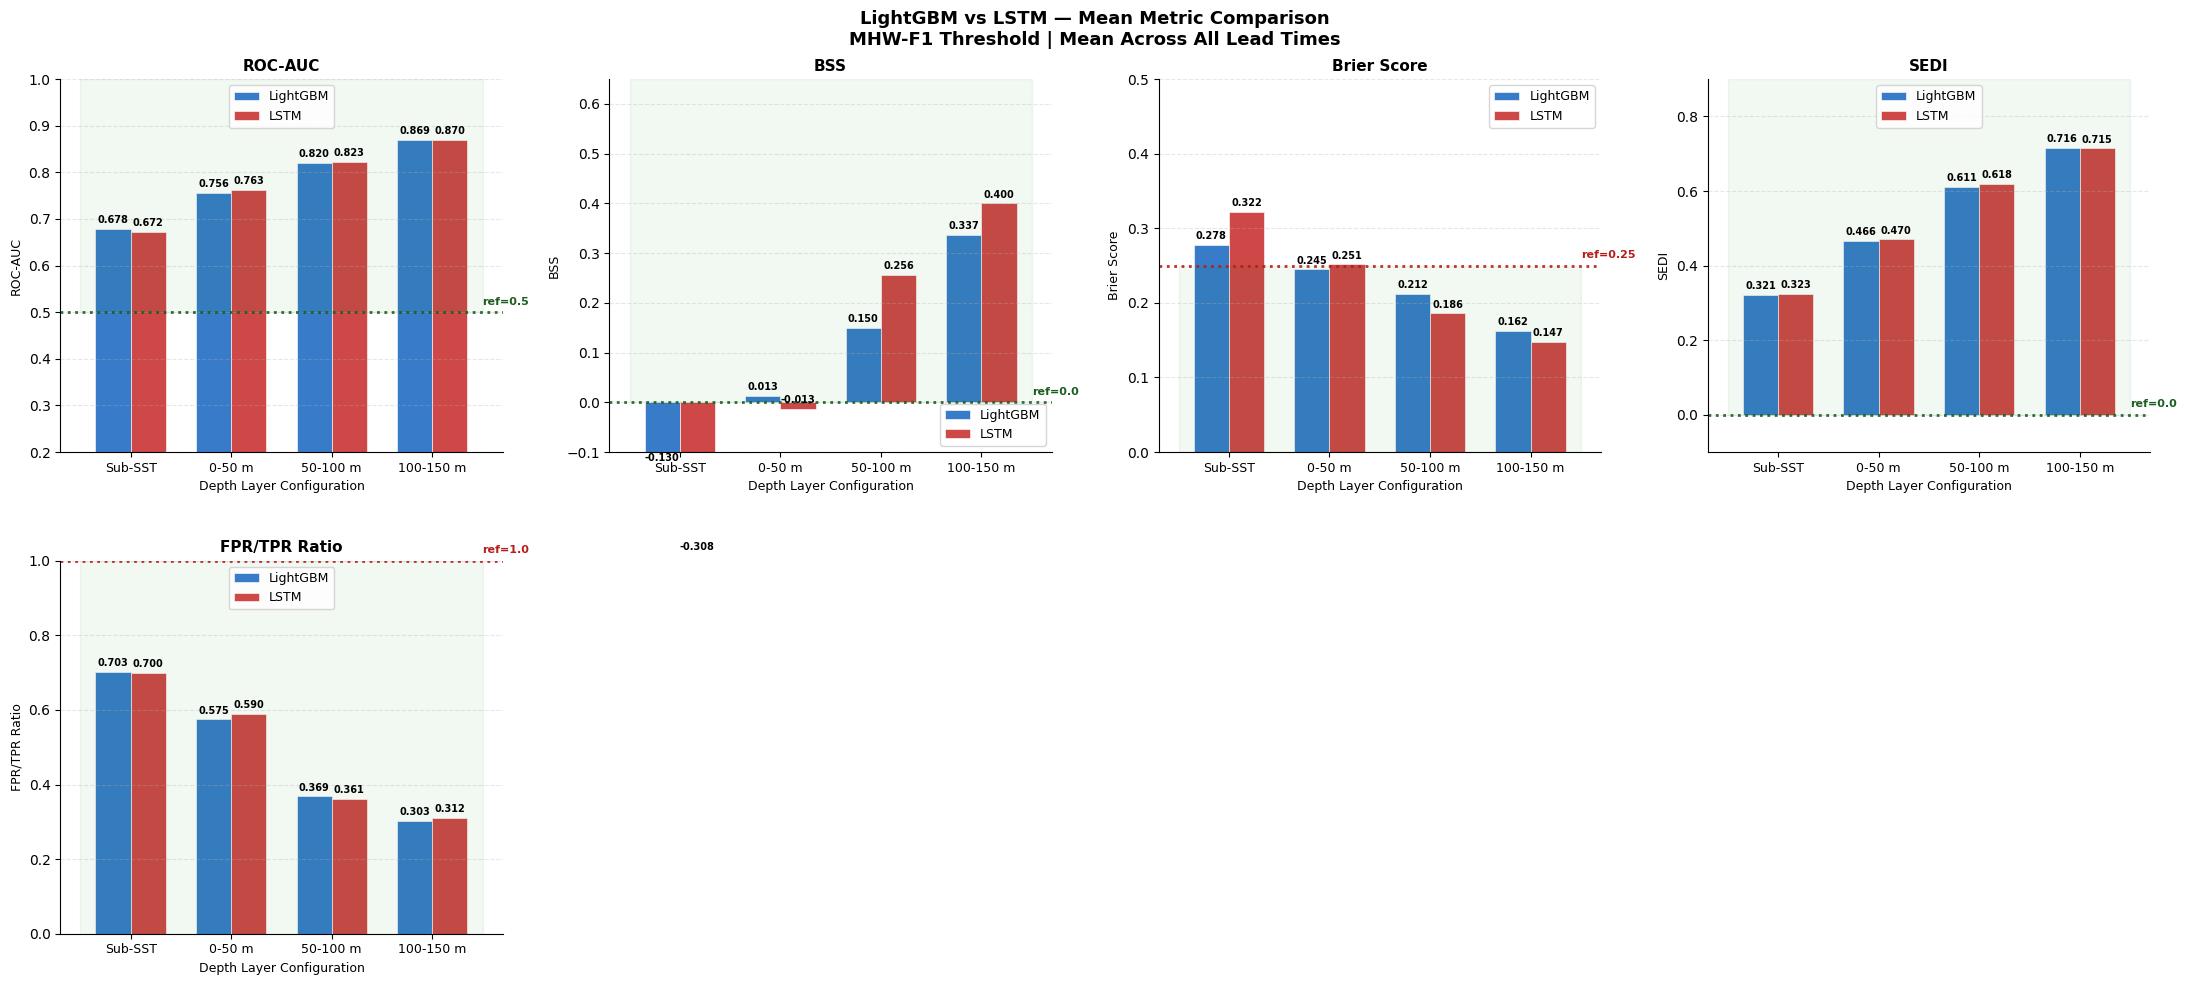

Saved: plot_compare_bar.png


In [14]:



n_metrics = len(metrics_compare)
n_cols    = 4
n_rows    = (n_metrics + n_cols - 1) // n_cols  # = 2 rows

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(22, 5 * n_rows)
)
fig.suptitle(
    'LightGBM vs LSTM — Mean Metric Comparison\n'
    'MHW-F1 Threshold | Mean Across All Lead Times',
    fontsize=13, fontweight='bold'
)
axes = axes.flatten()

x     = np.arange(len(CONFIGS))   # one group per config
width = 0.35                       # bar width

for idx, (metric, label, ref, ref_dir,
          ymin, ymax) in enumerate(metrics_compare):
    ax = axes[idx]

    # Compute mean per model per config across all lead times
    lgbm_means = [
        best_df[
            (best_df['model']  == 'LightGBM') &
            (best_df['config'] == c)
        ][metric].mean()
        for c in CONFIGS
    ]
    lstm_means = [
        best_df[
            (best_df['model']  == 'LSTM') &
            (best_df['config'] == c)
        ][metric].mean()
        for c in CONFIGS
    ]

    # LightGBM bars — left of group centre
    bars_lgbm = ax.bar(
        x - width/2,
        lgbm_means,
        width,
        label='LightGBM',
        color=C['LightGBM'],
        alpha=0.85,
        edgecolor='white',
        linewidth=0.5
    )
    # LSTM bars — right of group centre
    bars_lstm = ax.bar(
        x + width/2,
        lstm_means,
        width,
        label='LSTM',
        color=C['LSTM'],
        alpha=0.85,
        edgecolor='white',
        linewidth=0.5
    )

    # Value labels on top of each bar
    for bar in list(bars_lgbm) + list(bars_lstm):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + (ymax - ymin) * 0.01,
            f'{h:.3f}',
            ha='center', va='bottom',
            fontsize=7, fontweight='bold'
        )

    # Reference line (skill threshold)
    if ref is not None:
        ref_color = '#1B5E20' if ref_dir == 'min' \
            else '#B71C1C'
        ax.axhline(
            ref,
            color=ref_color,
            linestyle=':',
            linewidth=2.0,
            alpha=0.9
        )
        ax.text(
            x[-1] + 0.5,
            ref + (ymax - ymin) * 0.02,
            f'ref={ref}',
            fontsize=8,
            color=ref_color,
            fontweight='bold',
            ha='left'
        )

    # Shade good region
    if ref_dir == 'min':
        # Good = above ref line
        ax.fill_between(
            [-0.5, len(CONFIGS) - 0.5],
            ref, ymax,
            alpha=0.05, color='green'
        )
    else:
        # Good = below ref line
        ax.fill_between(
            [-0.5, len(CONFIGS) - 0.5],
            ymin, ref,
            alpha=0.05, color='green'
        )

    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel('Depth Layer Configuration', fontsize=9)
    ax.set_ylabel(label, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(
        [CONFIG_LABELS[c] for c in CONFIGS],
        fontsize=9
    )
    ax.set_ylim(ymin, ymax)
    ax.legend(fontsize=9, loc='best')
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide any unused subplots
for idx in range(n_metrics, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.savefig(
    EVAL_OUT_DIR / 'plot_compare_bar.png',
    dpi=1500, bbox_inches='tight'
)
plt.show()
print('Saved: plot_compare_bar.png')

### Each Metric Changes with Lead time

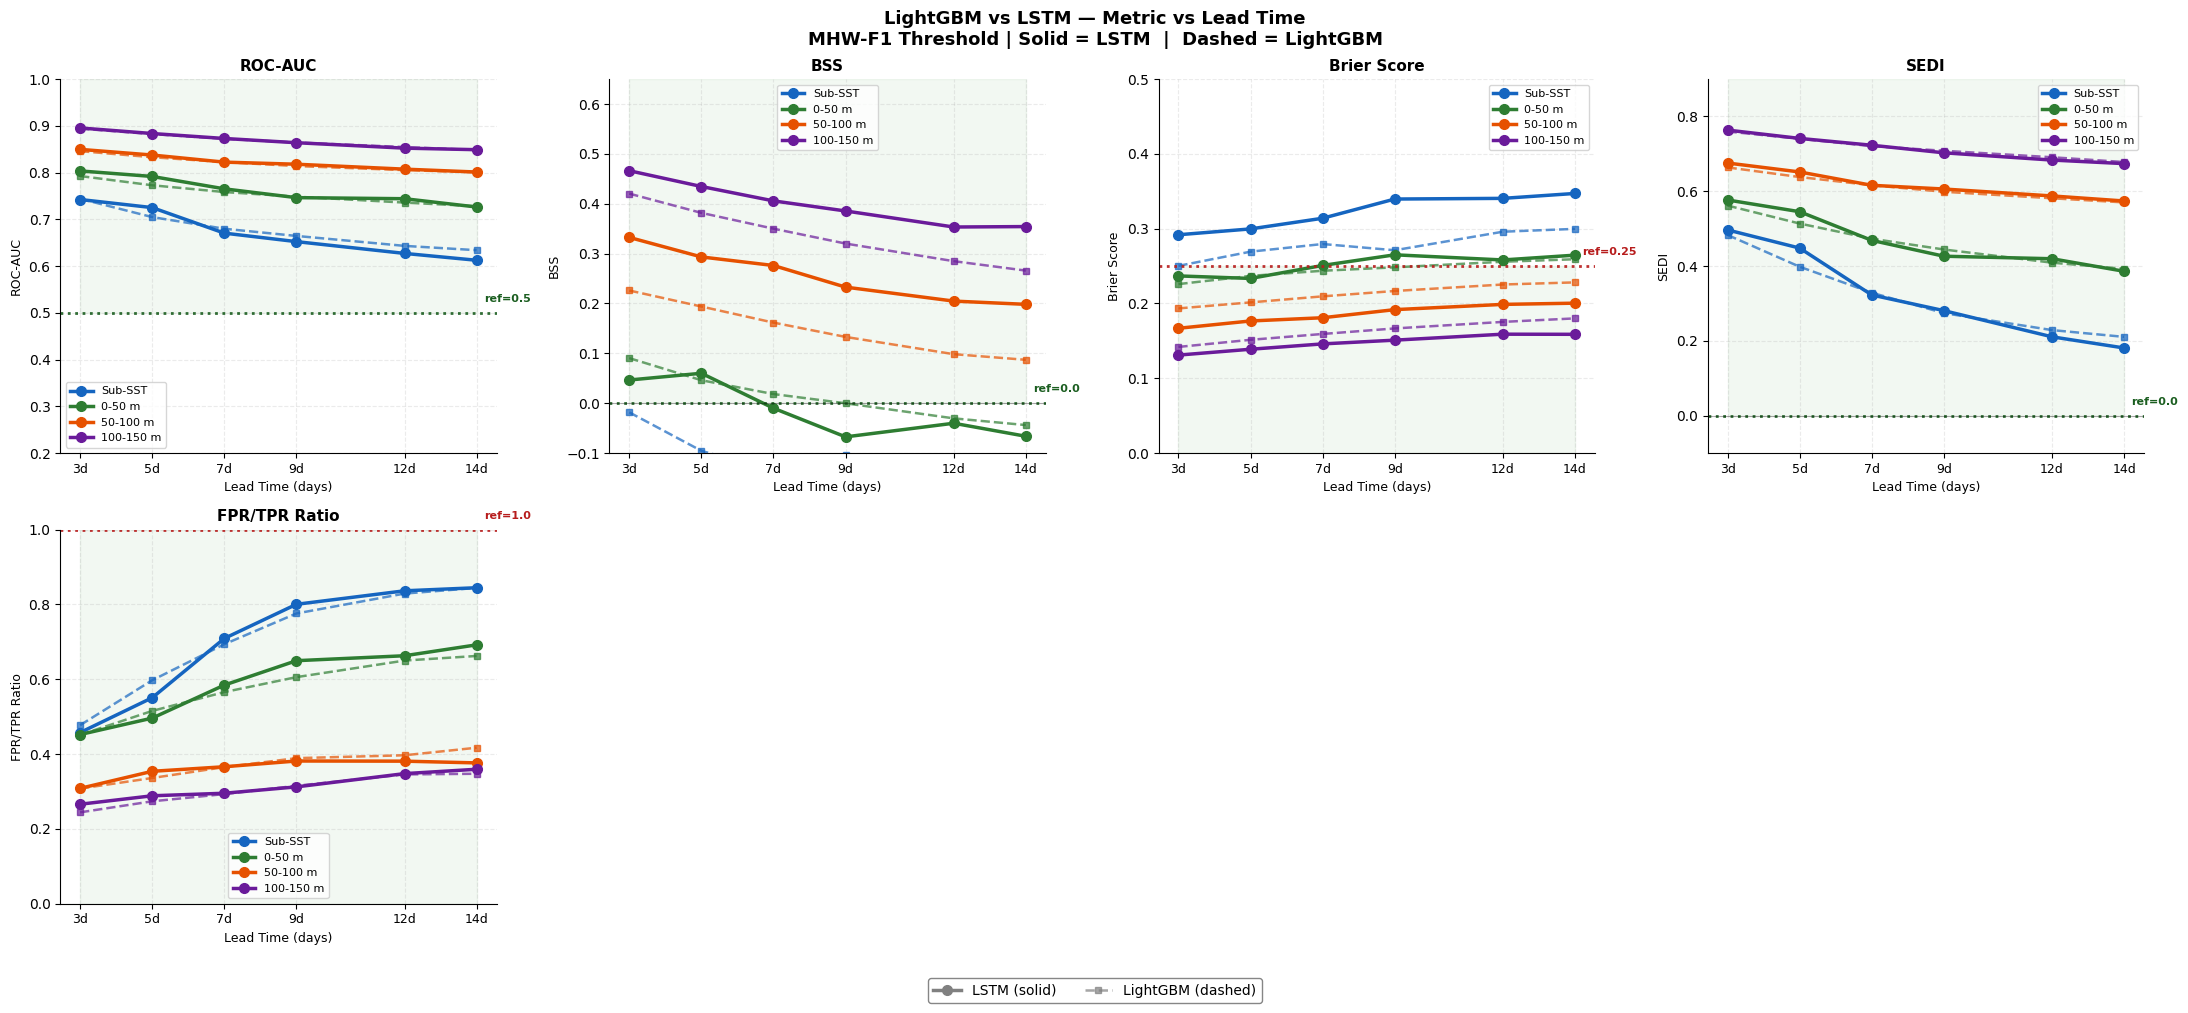

Saved: plot_compare_line.png


In [15]:

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(22, 5 * n_rows)
)
fig.suptitle(
    'LightGBM vs LSTM — Metric vs Lead Time\n'
    'MHW-F1 Threshold | '
    'Solid = LSTM  |  Dashed = LightGBM',
    fontsize=13, fontweight='bold'
)
axes = axes.flatten()

for idx, (metric, label, ref, ref_dir,
          ymin, ymax) in enumerate(metrics_compare):
    ax = axes[idx]

    for config in CONFIGS:
        for model, ls, lw, alpha, marker in zip(
            ['LSTM',    'LightGBM'],
            ['-',       '--'],
            [2.5,        1.8],
            [1.0,        0.7],
            ['o',        's']
        ):
            # Get metric values for this model+config
            # sorted by lead time
            sub = best_df[
                (best_df['model']  == model) &
                (best_df['config'] == config)
            ].sort_values('lead_time')

            ax.plot(
                sub['lead_time'],
                sub[metric],
                linestyle=ls,
                marker=marker,
                color=C[config],
                linewidth=lw,
                markersize=7 if model == 'LSTM' else 5,
                alpha=alpha,
                # Only label LSTM lines to avoid legend clutter
                label=CONFIG_LABELS[config]
                if model == 'LSTM' else ''
            )

    # Reference line
    if ref is not None:
        ref_color = '#1B5E20' if ref_dir == 'min' \
            else '#B71C1C'
        ax.axhline(
            ref,
            color=ref_color,
            linestyle=':',
            linewidth=2.0,
            alpha=0.9
        )
        offset = (ymax - ymin) * 0.03
        ax.text(
            LEAD_TIMES[-1] + 0.2,
            ref + offset,
            f'ref={ref}',
            fontsize=8,
            color=ref_color,
            fontweight='bold',
            ha='left'
        )

    # Shade good region
    if ref_dir == 'min':
        ax.fill_between(
            [LEAD_TIMES[0], LEAD_TIMES[-1]],
            ref, ymax,
            alpha=0.05, color='green'
        )
    else:
        ax.fill_between(
            [LEAD_TIMES[0], LEAD_TIMES[-1]],
            ymin, ref,
            alpha=0.05, color='green'
        )

    # BSS and SEDI zero reference
    if metric in ['bss', 'sedi']:
        ax.axhline(
            0, color='black',
            linestyle='-',
            linewidth=0.8, alpha=0.3
        )

    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel('Lead Time (days)', fontsize=9)
    ax.set_ylabel(label, fontsize=9)
    ax.set_xticks(LEAD_TIMES)
    ax.set_xticklabels(
        [f'{l}d' for l in LEAD_TIMES], fontsize=9
    )
    ax.set_ylim(ymin, ymax)
    ax.legend(fontsize=8, loc='best')
    ax.grid(alpha=0.25, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Model style legend — added to last visible subplot
legend_model = [
    Line2D(
        [0], [0], color='gray',
        linewidth=2.5, linestyle='-',
        marker='o', markersize=7,
        label='LSTM (solid)'
    ),
    Line2D(
        [0], [0], color='gray',
        linewidth=1.8, linestyle='--',
        marker='s', markersize=5,
        label='LightGBM (dashed)',
        alpha=0.7
    ),
]

# Hide unused subplots
for idx in range(n_metrics, len(axes)):
    axes[idx].set_visible(False)

# Add model legend to figure bottom
fig.legend(
    handles=legend_model,
    fontsize=10,
    loc='lower center',
    ncol=2,
    bbox_to_anchor=(0.5, -0.02),
    framealpha=0.95,
    edgecolor='gray'
)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(
    EVAL_OUT_DIR / 'plot_compare_line.png',
    dpi=1500, bbox_inches='tight'
)
plt.show()
print('Saved: plot_compare_line.png')


### All 7 Metrics as Grouped Bar Chart

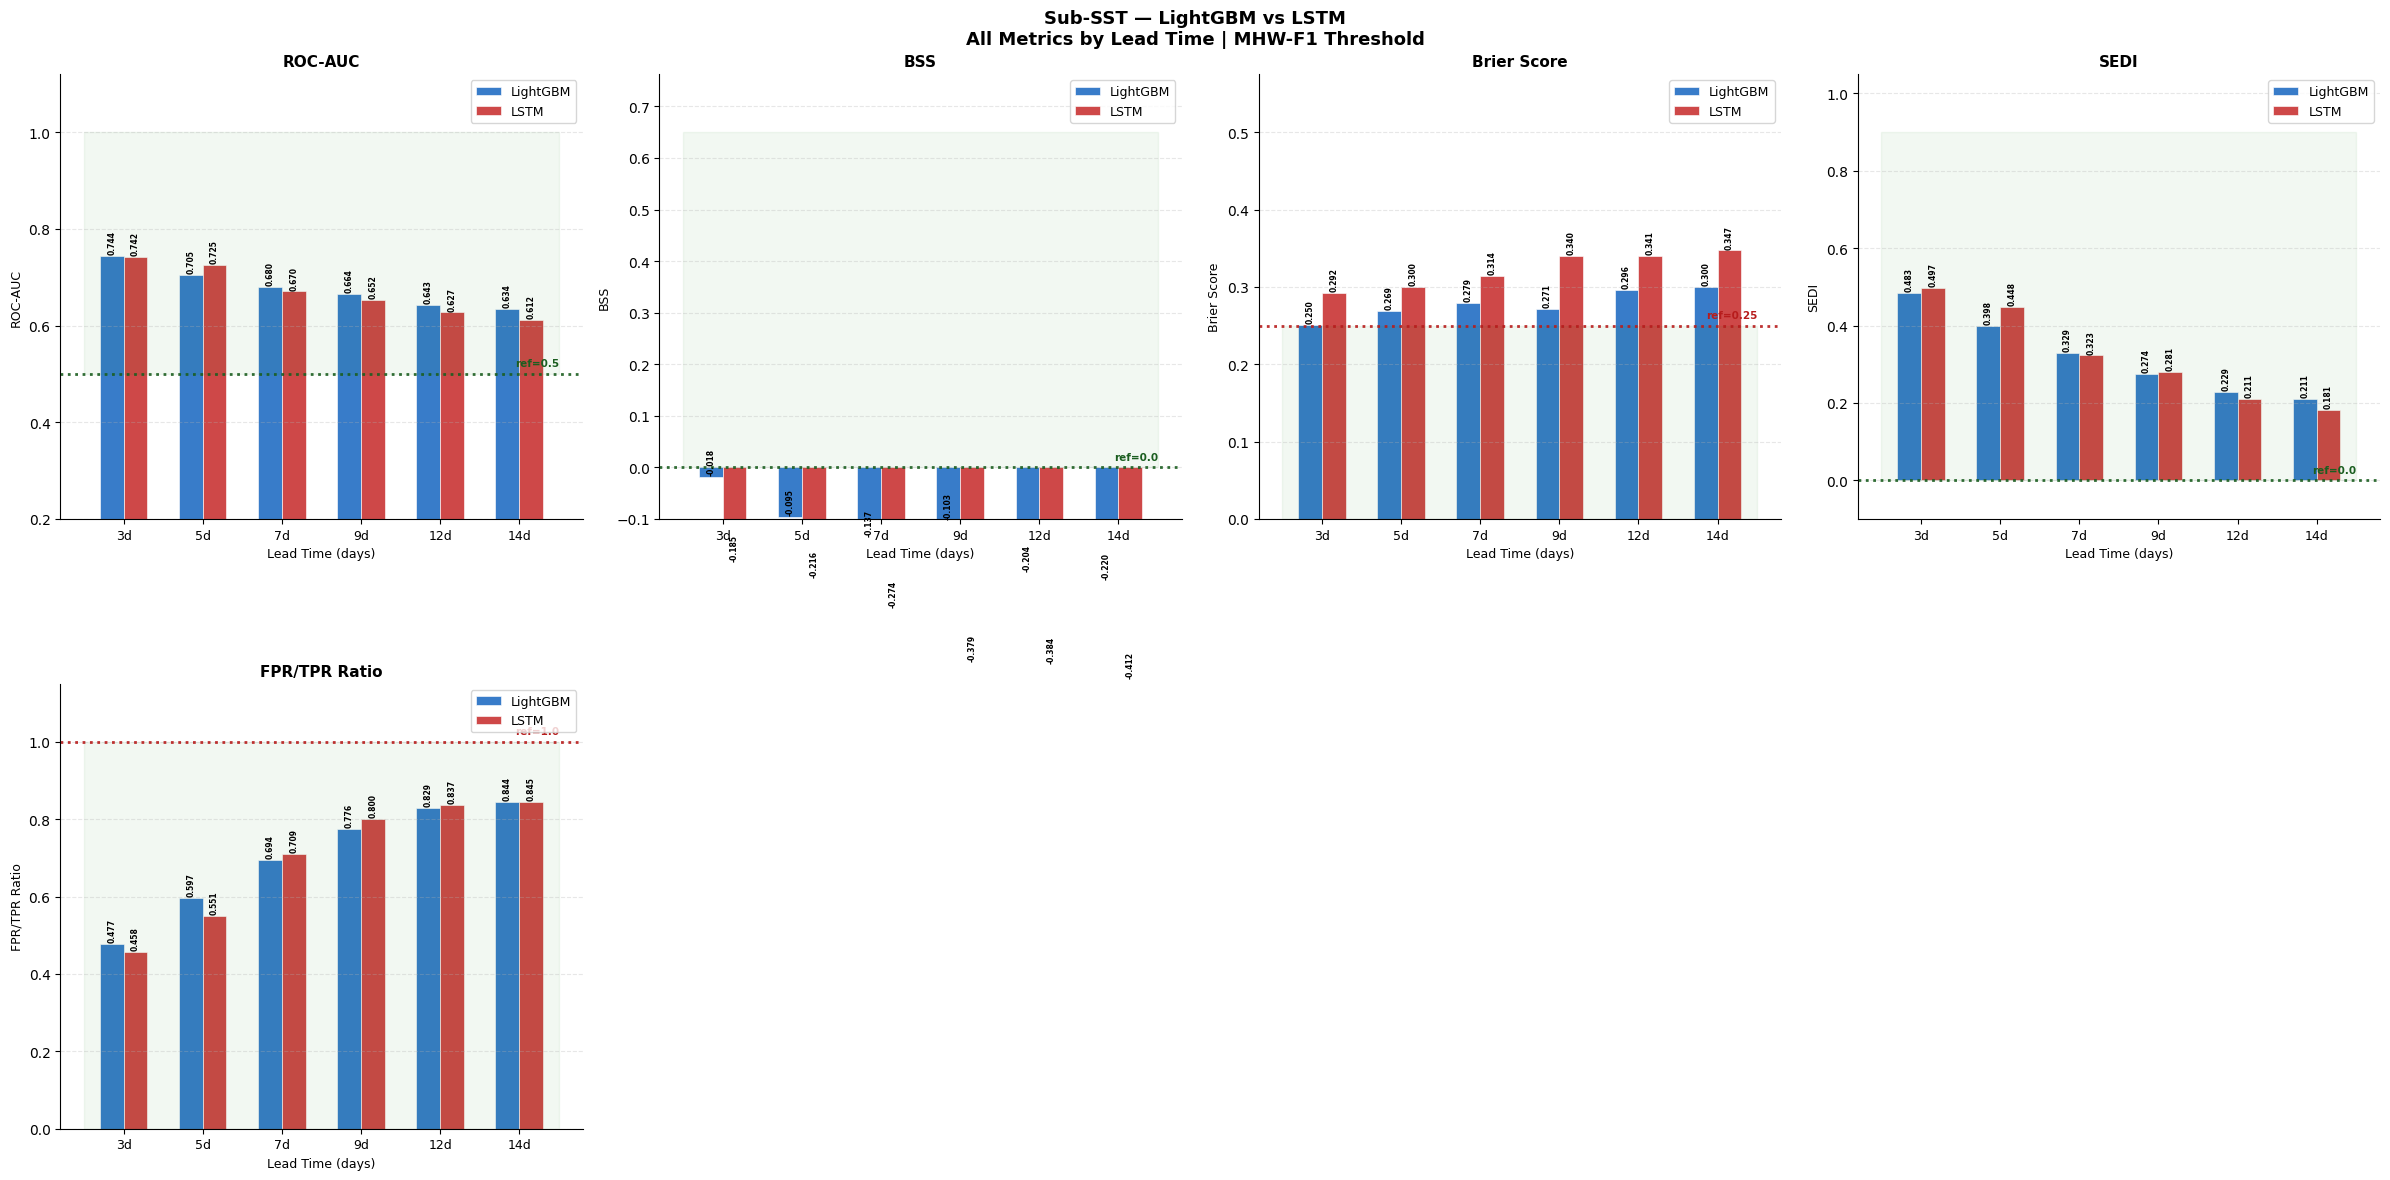

Saved: plot_compare_detail_SubSST.png


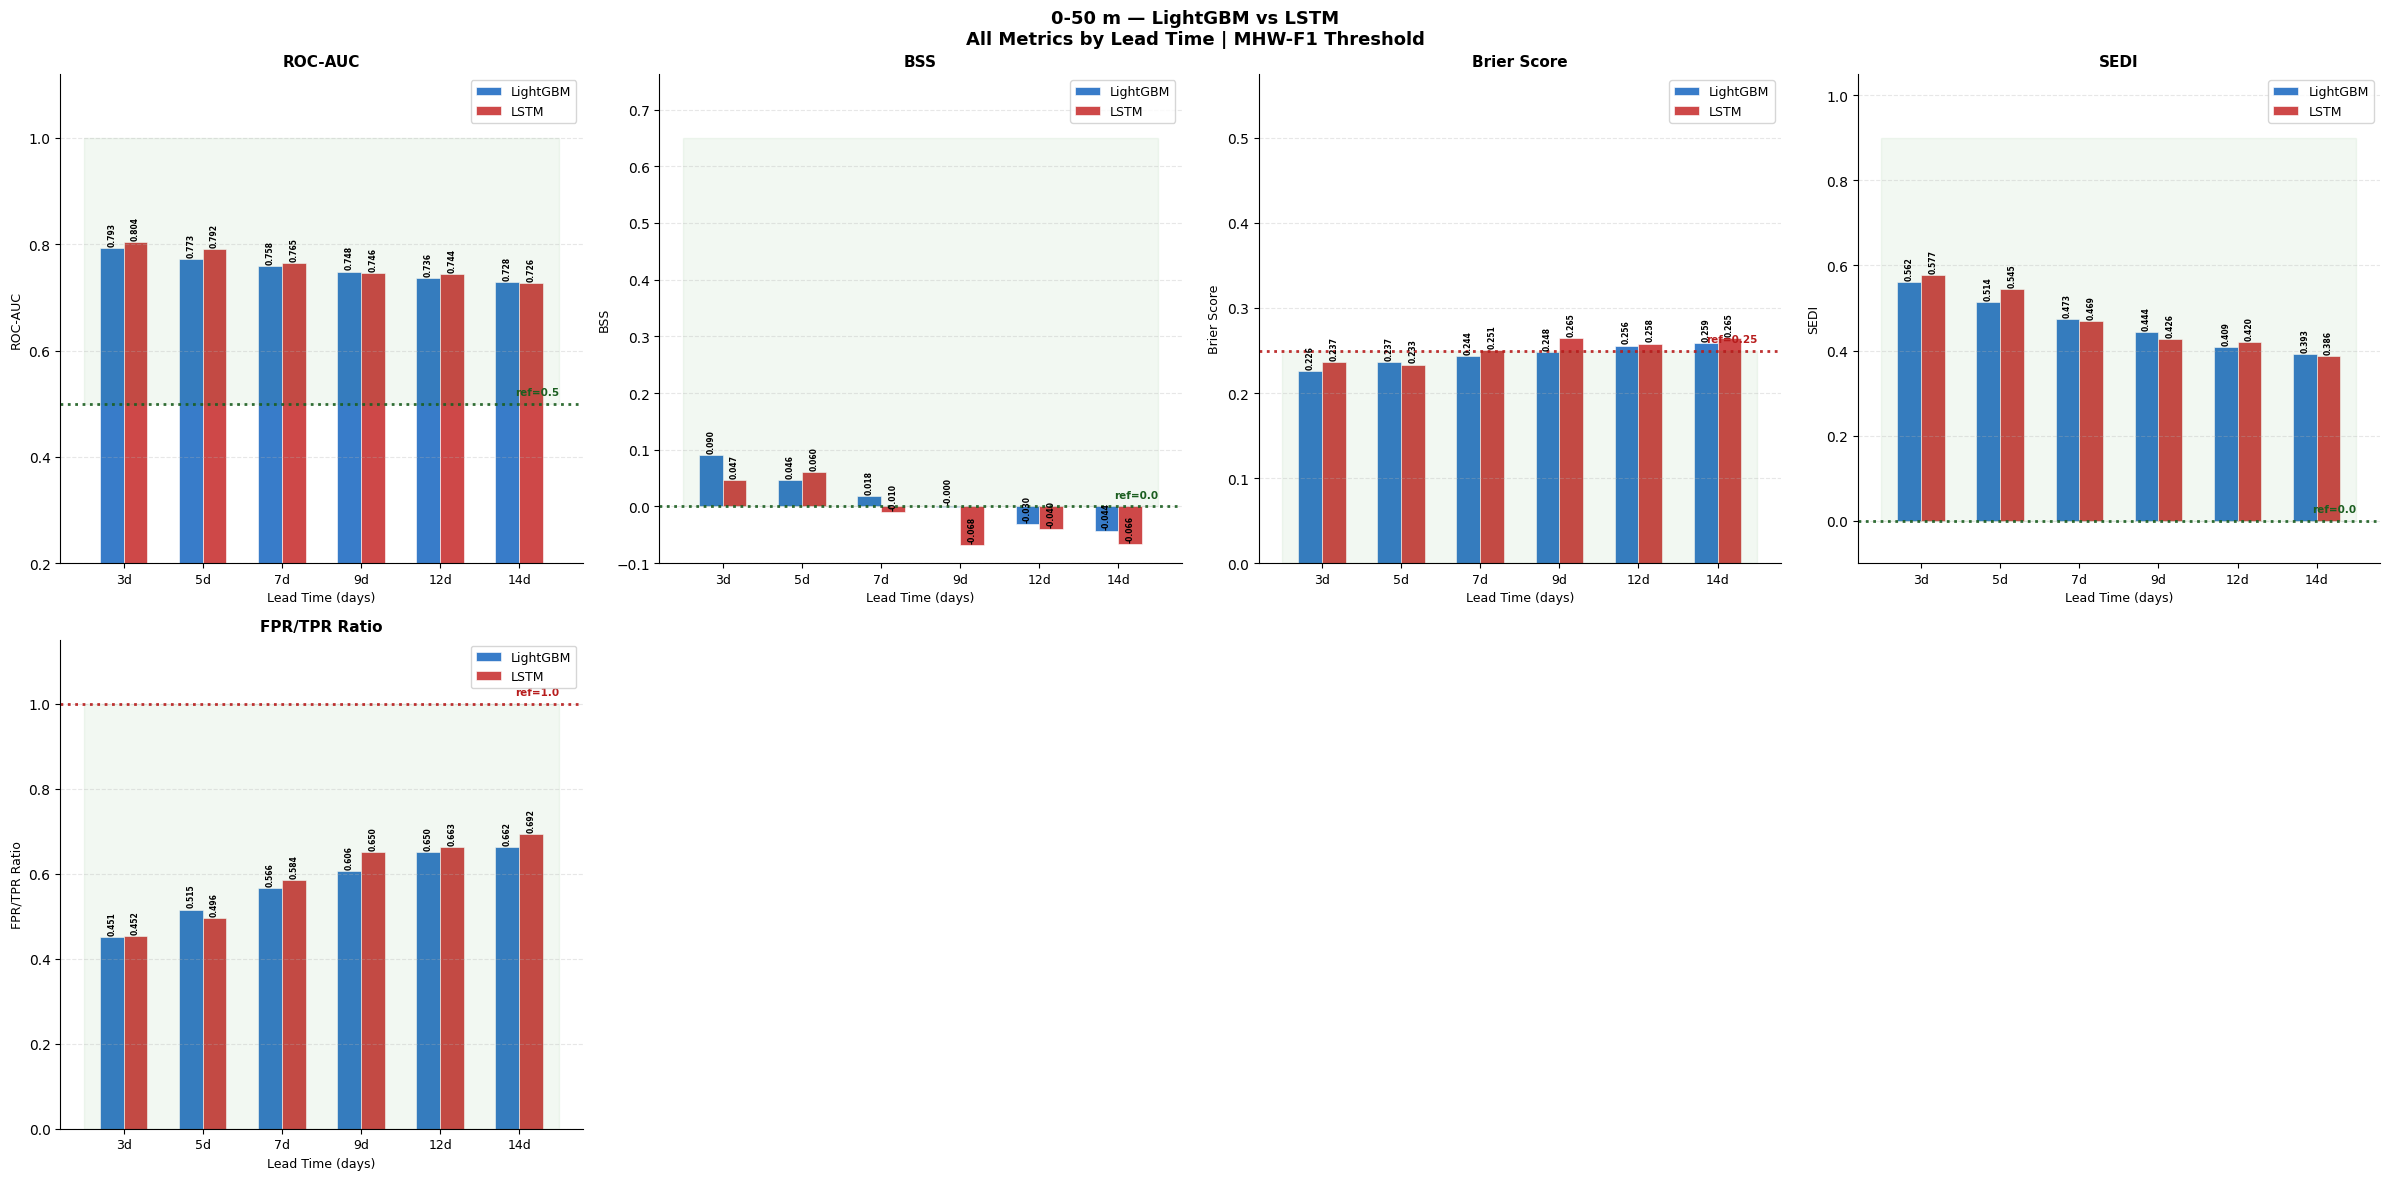

Saved: plot_compare_detail_050m.png


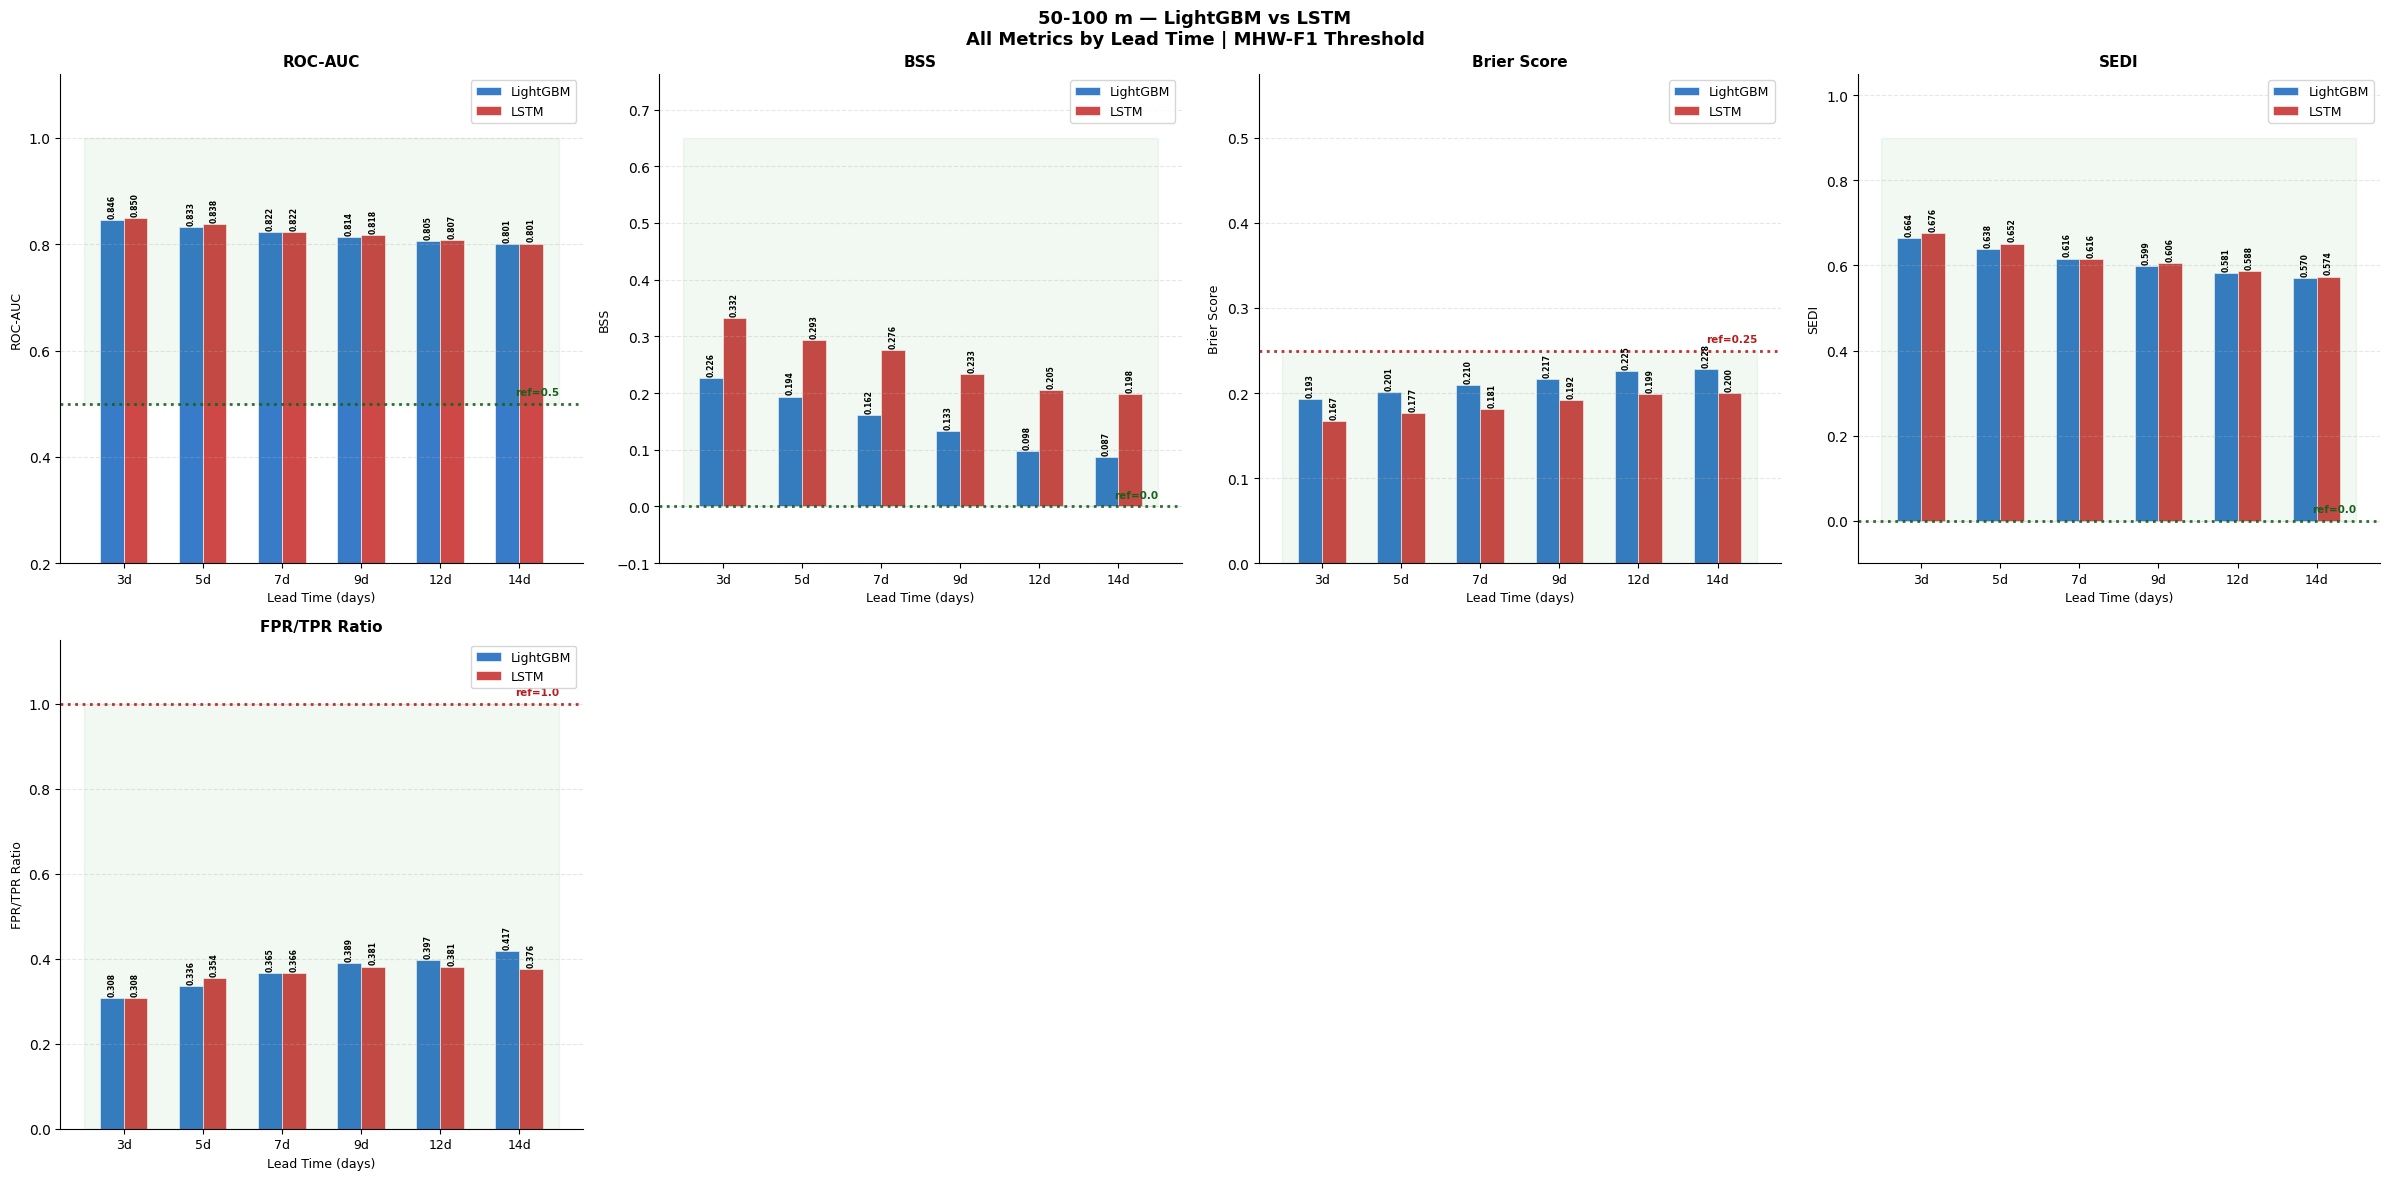

Saved: plot_compare_detail_50100m.png


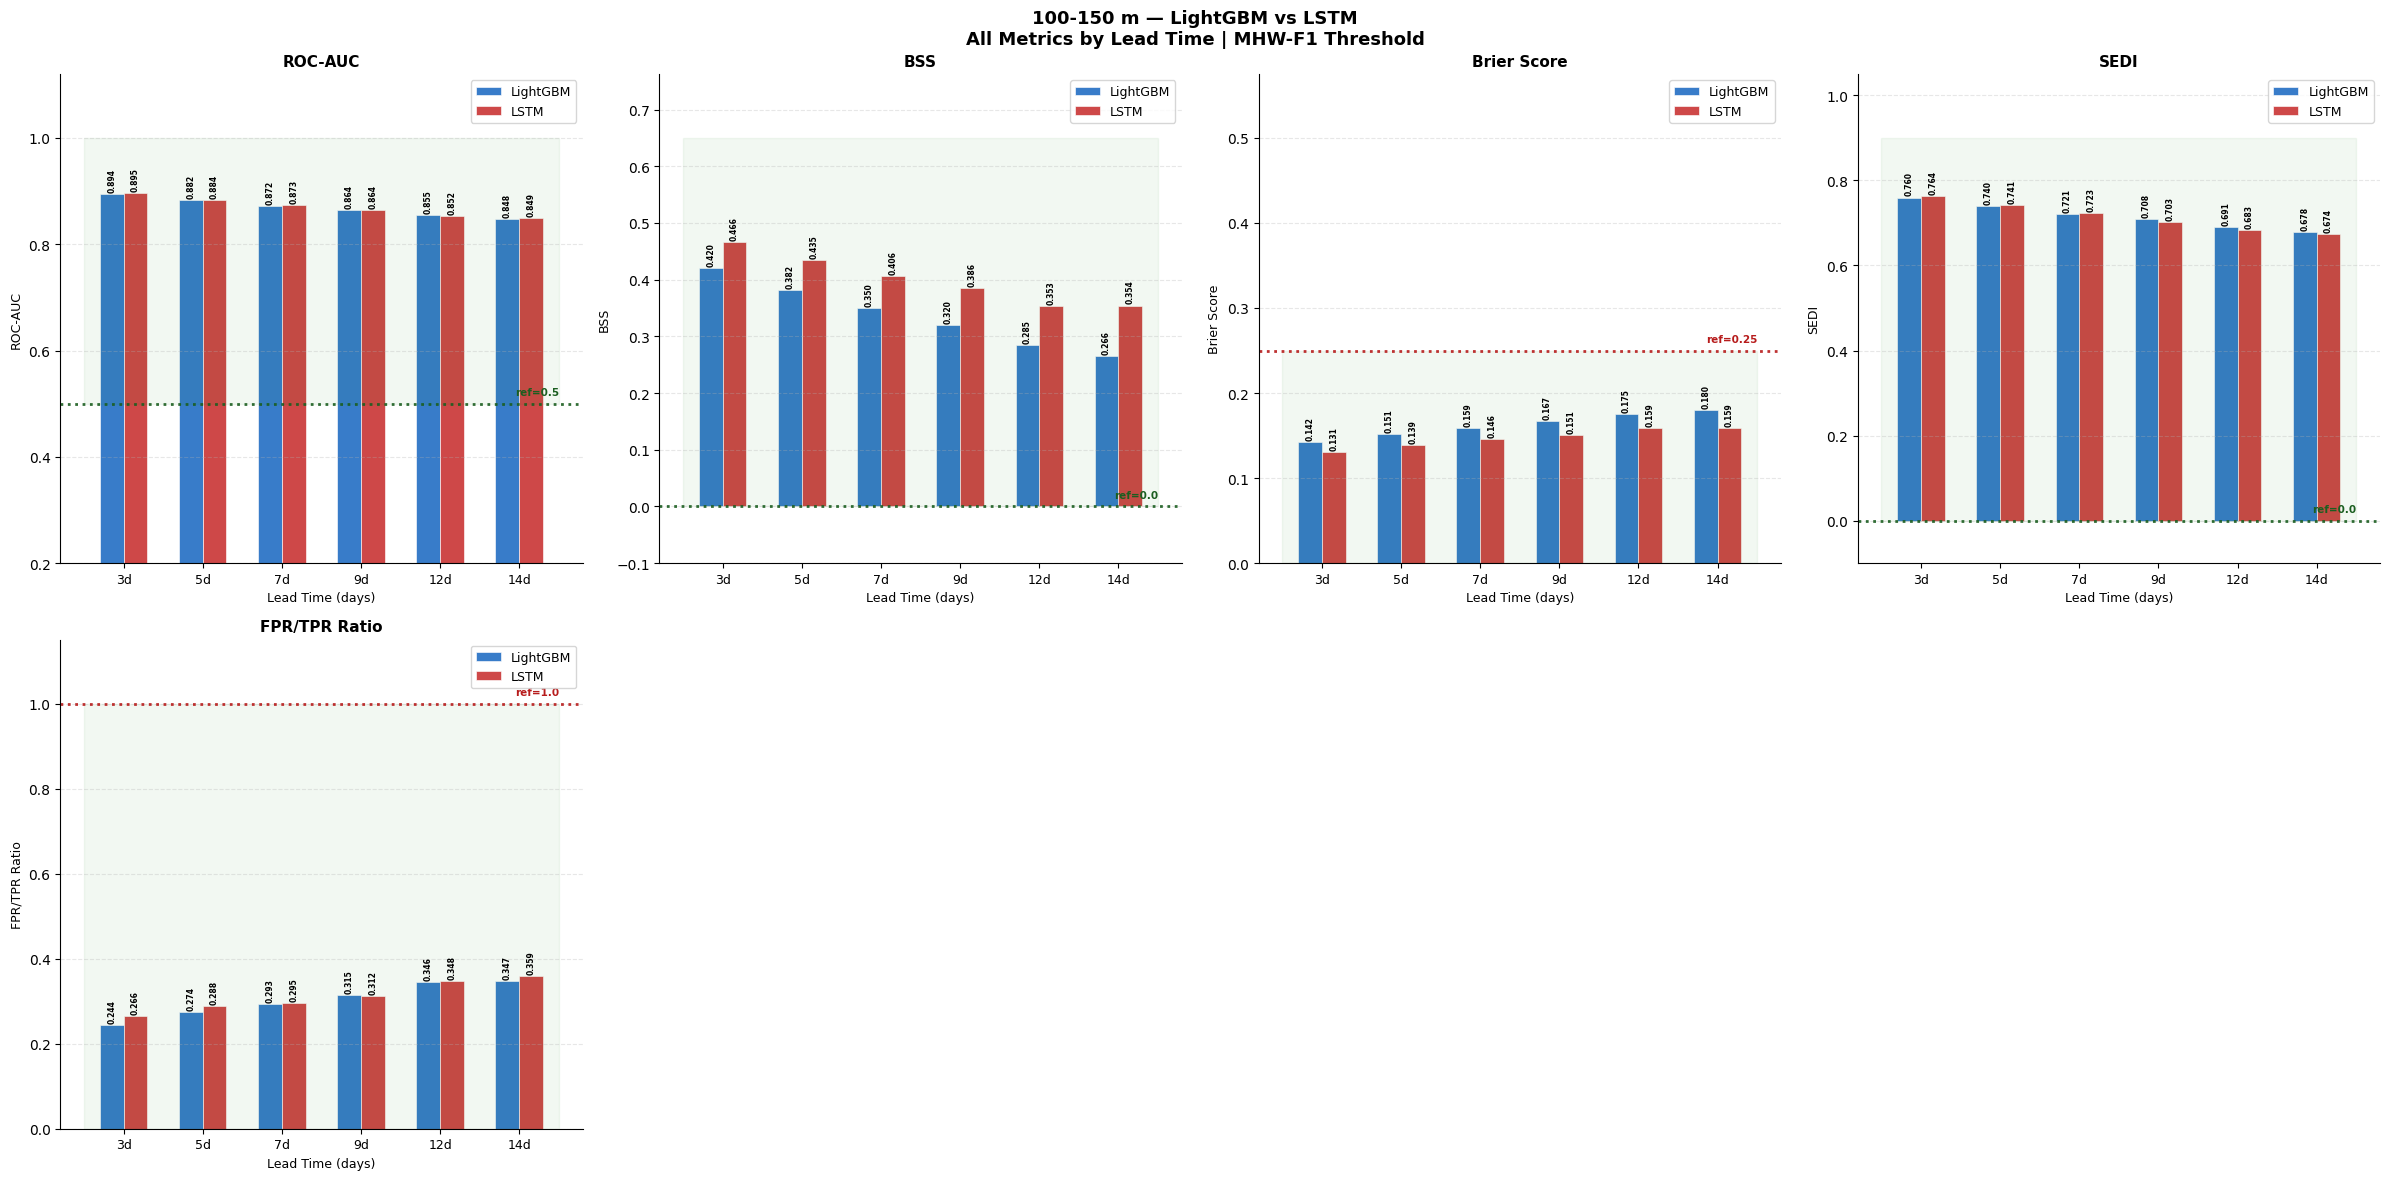

Saved: plot_compare_detail_100150m.png


In [16]:

for config in CONFIGS:

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(24, 6 * n_rows)  # taller for label space
    )
    fig.suptitle(
        f'{CONFIG_LABELS[config]} — LightGBM vs LSTM\n'
        f'All Metrics by Lead Time | MHW-F1 Threshold',
        fontsize=13, fontweight='bold'
    )
    axes = axes.flatten()

    x     = np.arange(len(LEAD_TIMES))
    width = 0.30  # slightly narrower — more space for labels

    for idx, (metric, label, ref, ref_dir,
              ymin, ymax) in enumerate(metrics_compare):
        ax = axes[idx]

        # LightGBM values per lead time
        lgbm_vals = [
            best_df[
                (best_df['model']     == 'LightGBM') &
                (best_df['config']    == config) &
                (best_df['lead_time'] == lead)
            ][metric].values[0]
            if len(best_df[
                (best_df['model']     == 'LightGBM') &
                (best_df['config']    == config) &
                (best_df['lead_time'] == lead)
            ]) > 0 else np.nan
            for lead in LEAD_TIMES
        ]

        # LSTM values per lead time
        lstm_vals = [
            best_df[
                (best_df['model']     == 'LSTM') &
                (best_df['config']    == config) &
                (best_df['lead_time'] == lead)
            ][metric].values[0]
            if len(best_df[
                (best_df['model']     == 'LSTM') &
                (best_df['config']    == config) &
                (best_df['lead_time'] == lead)
            ]) > 0 else np.nan
            for lead in LEAD_TIMES
        ]

        bars_lgbm = ax.bar(
            x - width/2, lgbm_vals, width,
            label='LightGBM',
            color=C['LightGBM'],
            alpha=0.85,
            edgecolor='white',
            linewidth=0.5
        )
        bars_lstm = ax.bar(
            x + width/2, lstm_vals, width,
            label='LSTM',
            color=C['LSTM'],
            alpha=0.85,
            edgecolor='white',
            linewidth=0.5
        )

        # Value labels — rotated 90° to avoid clashing
        for bar in list(bars_lgbm) + list(bars_lstm):
            h = bar.get_height()
            if not np.isnan(h):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h + (ymax - ymin) * 0.005,
                    f'{h:.3f}',
                    ha='center',
                    va='bottom',
                    fontsize=5.5,
                    fontweight='bold',
                    rotation=90
                )

        # Reference line
        if ref is not None:
            ref_color = '#1B5E20' if ref_dir == 'min' \
                else '#B71C1C'
            ax.axhline(
                ref,
                color=ref_color,
                linestyle=':',
                linewidth=2.0,
                alpha=0.9
            )
            # Reference label on right side
            ax.text(
                len(LEAD_TIMES) - 0.5,
                ref + (ymax - ymin) * 0.02,
                f'ref={ref}',
                fontsize=7.5,
                color=ref_color,
                fontweight='bold',
                ha='right'
            )

        # Shade good region
        if ref is not None:
            if ref_dir == 'min':
                ax.fill_between(
                    [-0.5, len(LEAD_TIMES) - 0.5],
                    ref, ymax,
                    alpha=0.05, color='green'
                )
            else:
                ax.fill_between(
                    [-0.5, len(LEAD_TIMES) - 0.5],
                    ymin, ref,
                    alpha=0.05, color='green'
                )

        # Extend y-axis top by 15% for label space
        ax.set_ylim(
            ymin,
            ymax + (ymax - ymin) * 0.15
        )

        ax.set_title(
            label, fontsize=11, fontweight='bold'
        )
        ax.set_xlabel('Lead Time (days)', fontsize=9)
        ax.set_ylabel(label, fontsize=9)
        ax.set_xticks(x)
        ax.set_xticklabels(
            [f'{l}d' for l in LEAD_TIMES],
            fontsize=9
        )
        ax.legend(fontsize=9, loc='upper right')
        ax.grid(
            axis='y', alpha=0.3, linestyle='--'
        )
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    # Hide unused subplots
    for idx in range(n_metrics, len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    fname = (
        f'plot_compare_detail_'
        f'{config.replace("-", "").replace(" ", "_")}.png'
    )
    plt.savefig(
        EVAL_OUT_DIR / f'{fname}',
        dpi=300, bbox_inches='tight'
    )
    plt.show()
    print(f'Saved: {fname}')

In [17]:
print(shap_df.columns.tolist())
print(shap_df.head(5).to_string())
print(f'Shape: {shap_df.shape}')
print(f'Configs:   {shap_df["config"].unique()}')
print(f'Models:    {shap_df["model"].unique()}')
print(f'Lead times:{shap_df["lead_time"].unique()}')
print(f'Features:  {shap_df["feature"].unique()}')

['config', 'target', 'lead_time', 'feature', 'shap_importance', 'rank', 'model']
    config   target  lead_time      feature  shap_importance  rank     model
0  Sub-SST  mhw_sst          3          sst        32.239912     1  LightGBM
1  Sub-SST  mhw_sst          3     ssr_flux        20.451961     2  LightGBM
2  Sub-SST  mhw_sst          3          t2m         9.447059     3  LightGBM
3  Sub-SST  mhw_sst          3          msl         7.778123     4  LightGBM
4  Sub-SST  mhw_sst          3  latent_flux         7.189101     5  LightGBM
Shape: (528, 7)
Configs:   ['Sub-SST' '0-50m' '50-100m' '100-150m']
Models:    ['LightGBM' 'LSTM']
Lead times:[ 3  5  7  9 12 14]
Features:  ['sst' 'ssr_flux' 't2m' 'msl' 'latent_flux' 'temp_0_50m' 'wind_speed'
 'str_flux' 'sensible_flux' 'temp_100_150m' 'temp_50_100m']




---



---







# Feaure Importance Section

In [18]:


# Feature display names — shorter for plots
FEATURE_LABELS = {
    'sst':           'SST',
    'temp_0_50m':    'Temp 0-50m',
    'temp_50_100m':  'Temp 50-100m',
    'temp_100_150m': 'Temp 100-150m',
    'ssr_flux':      'SW Radiation',
    'str_flux':      'LW Radiation',
    'latent_flux':   'Latent Heat',
    'sensible_flux': 'Sensible Heat',
    't2m':           '2m Air Temp',
    'msl':           'Sea Level Pressure',
    'wind_speed':    'Wind Speed',
}

# Feature categories for colour coding
# Atmospheric = warm colours | Ocean = cool colours
FEATURE_COLORS = {
    'SST':              '#1565C0',  # dark blue — ocean surface
    'Temp 0-50m':       '#1E88E5',  # blue — shallow ocean
    'Temp 50-100m':     '#42A5F5',  # light blue — mid ocean
    'Temp 100-150m':    '#90CAF9',  # very light blue — deep ocean
    'SW Radiation':     '#E65100',  # dark orange — atmospheric
    'LW Radiation':     '#F57C00',  # orange — atmospheric
    'Latent Heat':      '#FF9800',  # amber — atmospheric
    'Sensible Heat':    '#FFC107',  # yellow — atmospheric
    '2m Air Temp':      '#D32F2F',  # red — atmospheric
    'Sea Level Pressure':'#C62828', # dark red — atmospheric
    'Wind Speed':       '#AD1457',  # purple — atmospheric
}

# All features in display name form
ALL_FEATURES_DISPLAY = list(FEATURE_LABELS.values())

# get display name
def feat_label(f):
    return FEATURE_LABELS.get(f, f)

### Feature Importance by Depth Layer and Model
Mean Absolute SHAP Values - Averaged Across All Lead Times

Generating SHAP plots...


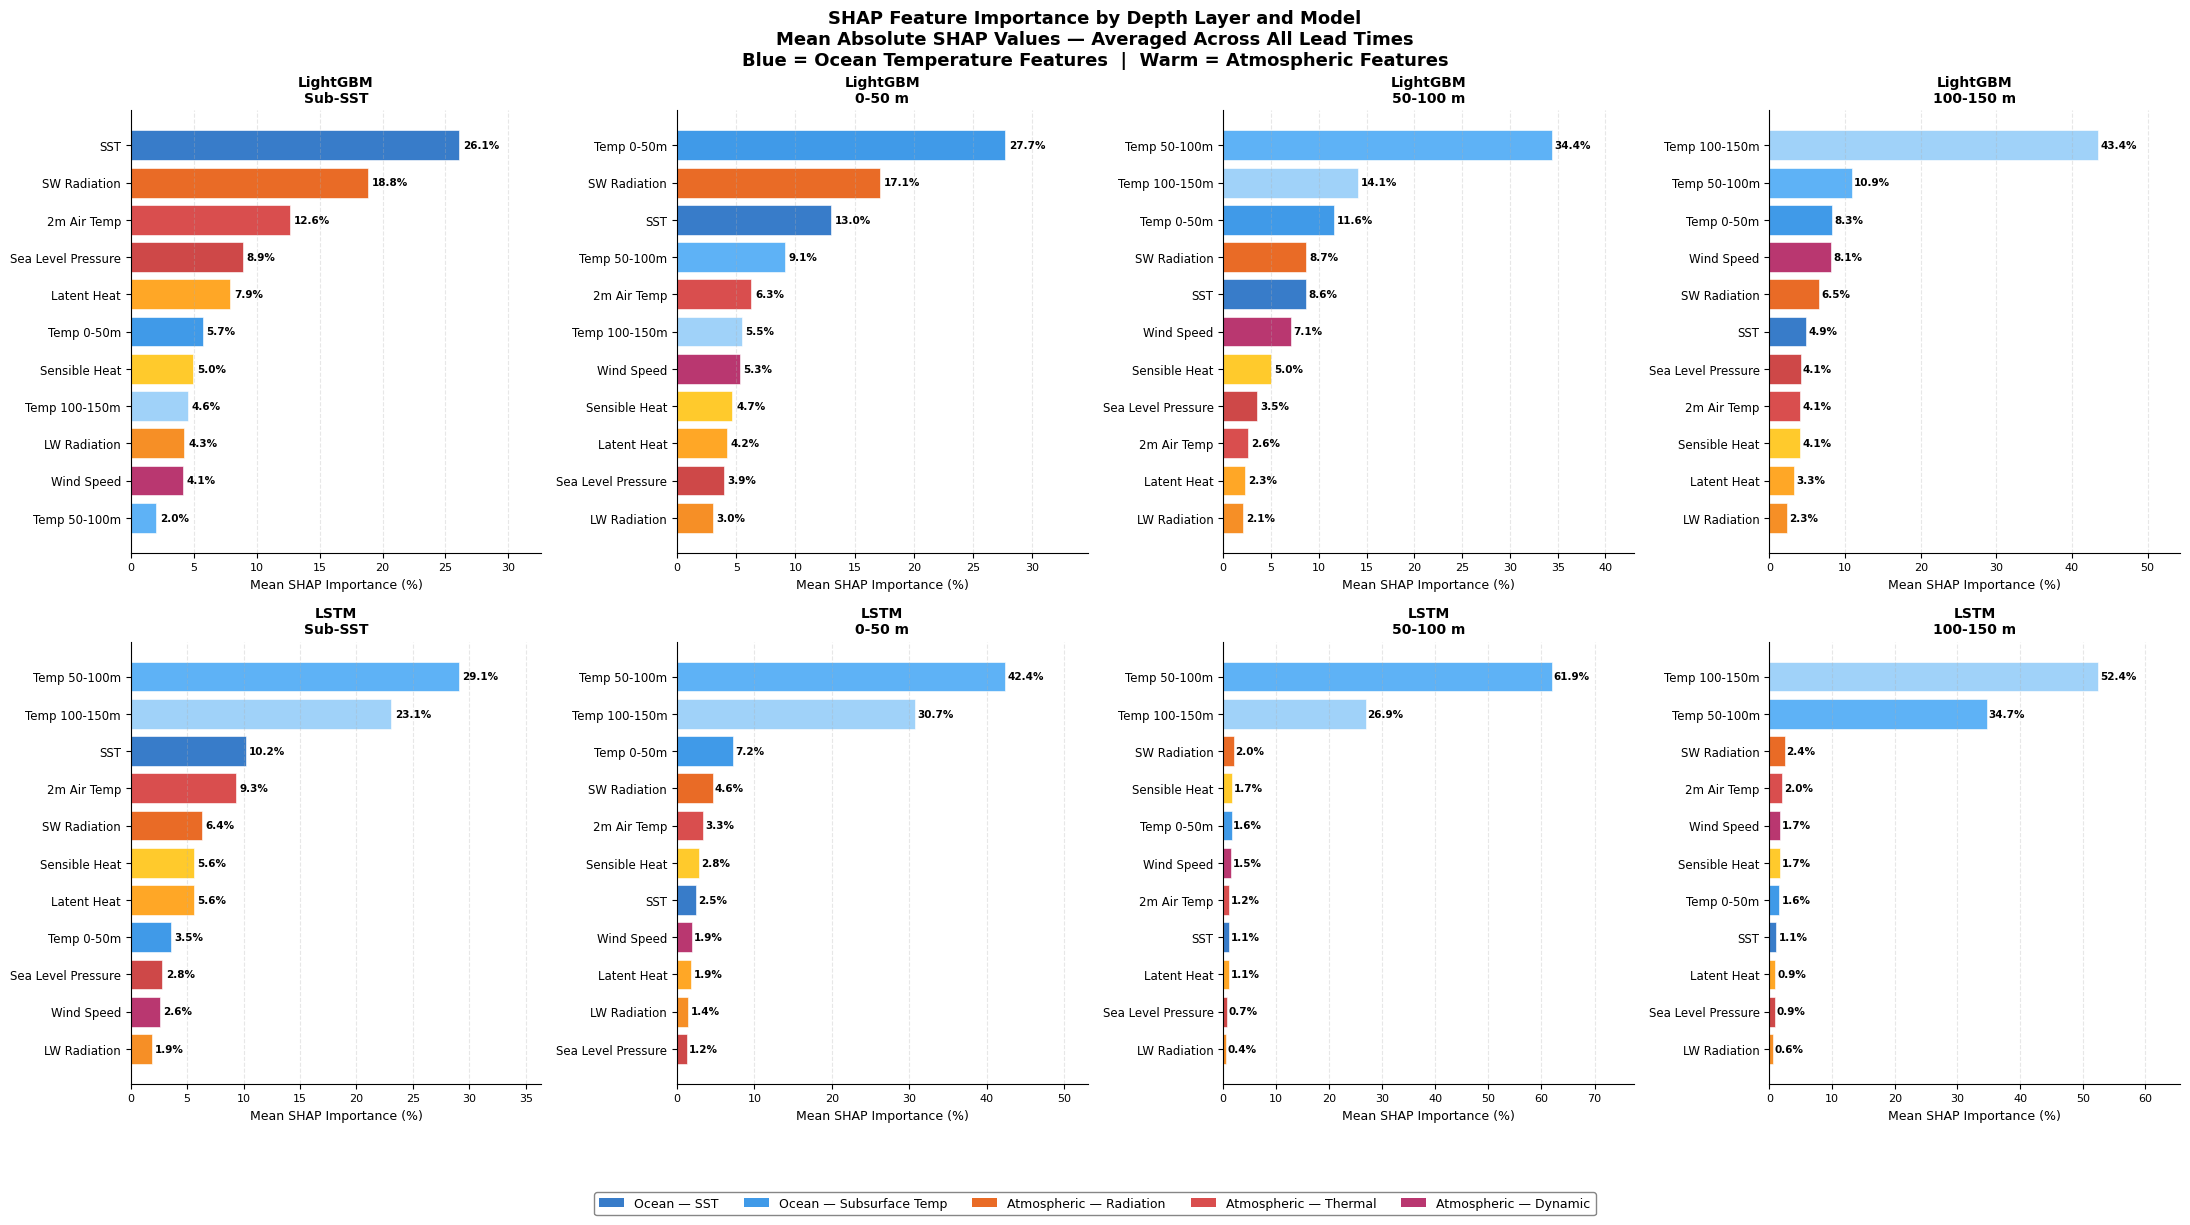

Saved: shap1_bar_chart.png


In [19]:


print('Generating SHAP plots...')


# Prepare data
# Mean SHAP per feature per config per model
# averaged across all lead times
shap_mean = shap_df.groupby(
    ['model', 'config', 'feature']
)['shap_importance'].mean().reset_index()
shap_mean['feature_label'] = shap_mean['feature'].map(
    feat_label
)


# Horizontal bars — features sorted by importance
# Shows which features matter most for each depth layer
fig, axes = plt.subplots(2, 4, figsize=(22, 12))
fig.suptitle(
    'SHAP Feature Importance by Depth Layer and Model\n'
    'Mean Absolute SHAP Values — Averaged Across All Lead Times\n'
    'Blue = Ocean Temperature Features  |  '
    'Warm = Atmospheric Features',
    fontsize=13, fontweight='bold'
)

for row, model in enumerate(MODELS):
    for col, config in enumerate(CONFIGS):
        ax = axes[row, col]

        # Get data for this model+config
        # sorted ascending so longest bar is at top
        sub = shap_mean[
            (shap_mean['model']  == model) &
            (shap_mean['config'] == config)
        ].sort_values('shap_importance', ascending=True)

        # Colour each bar by feature category
        bar_colors = [
            FEATURE_COLORS.get(fl, '#666666')
            for fl in sub['feature_label']
        ]

        bars = ax.barh(
            sub['feature_label'],
            sub['shap_importance'],
            color=bar_colors,
            alpha=0.85,
            edgecolor='white',
            linewidth=0.5
        )

        # Value labels at end of each bar
        for bar in bars:
            w = bar.get_width()
            ax.text(
                w + 0.3,
                bar.get_y() + bar.get_height() / 2,
                f'{w:.1f}%',
                va='center', fontsize=7.5,
                fontweight='bold'
            )

        ax.set_title(
            f'{model}\n{CONFIG_LABELS[config]}',
            fontsize=10, fontweight='bold'
        )
        ax.set_xlabel('Mean SHAP Importance (%)', fontsize=9)
        ax.set_xlim(0, sub['shap_importance'].max() * 1.25)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.tick_params(axis='y', labelsize=8.5)
        ax.tick_params(axis='x', labelsize=8)
        ax.grid(axis='x', alpha=0.3, linestyle='--')

# Add feature category legend
from matplotlib.patches import Patch
legend_els = [
    Patch(facecolor='#1565C0', alpha=0.85,
          label='Ocean — SST'),
    Patch(facecolor='#1E88E5', alpha=0.85,
          label='Ocean — Subsurface Temp'),
    Patch(facecolor='#E65100', alpha=0.85,
          label='Atmospheric — Radiation'),
    Patch(facecolor='#D32F2F', alpha=0.85,
          label='Atmospheric — Thermal'),
    Patch(facecolor='#AD1457', alpha=0.85,
          label='Atmospheric — Dynamic'),
]
fig.legend(
    handles=legend_els,
    fontsize=9,
    loc='lower center',
    ncol=len(legend_els),
    bbox_to_anchor=(0.5, -0.03),
    framealpha=0.95,
    edgecolor='gray'
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(
    EVAL_OUT_DIR / f'shap1_bar_chart.png',
    dpi=1500, bbox_inches='tight'
)
plt.show()
print('Saved: shap1_bar_chart.png')


### Feature Importance Heatmap
  Feature x Depth Layer Configuration (Mean Across All Lead Times)

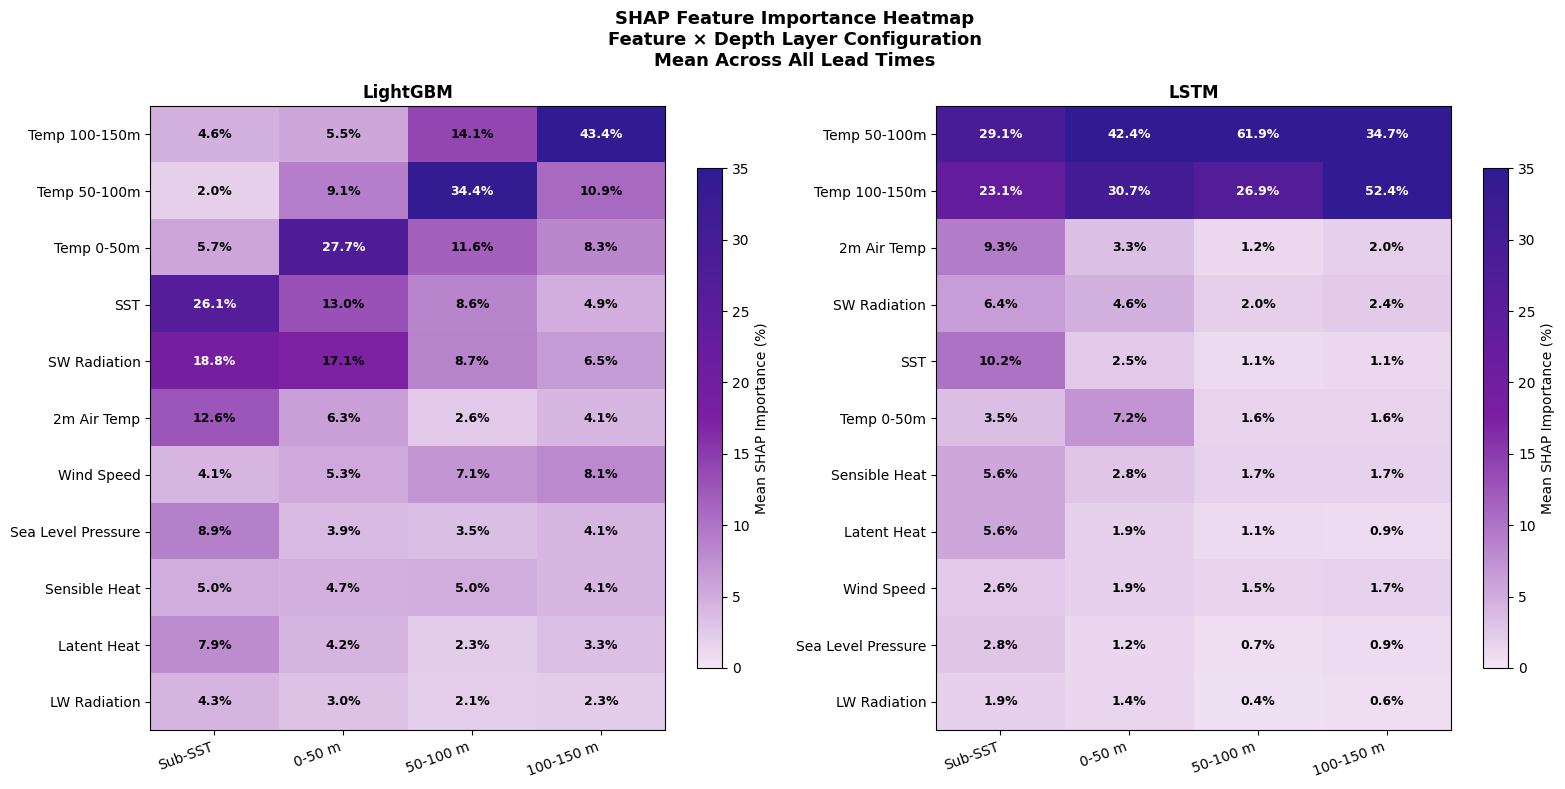

Saved: shap2_heatmap.png


In [20]:

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle(
    'SHAP Feature Importance Heatmap\n'
    'Feature × Depth Layer Configuration\n'
    'Mean Across All Lead Times',
    fontsize=13, fontweight='bold'
)

cmap_shap = LinearSegmentedColormap.from_list(
    'shap', ['#F3E5F5', '#7B1FA2', '#311B92']
)

for ax, model in zip(axes, MODELS):

    # Pivot: rows = features, cols = configs
    pivot = shap_mean[
        shap_mean['model'] == model
    ].pivot(
        index='feature_label',
        columns='config',
        values='shap_importance'
    )

    # Reorder columns to match CONFIGS order
    pivot = pivot.reindex(columns=CONFIGS)
    pivot.columns = [CONFIG_LABELS[c] for c in CONFIGS]

    # Sort rows by total importance across all configs
    pivot = pivot.loc[
        pivot.sum(axis=1).sort_values(
            ascending=False
        ).index
    ]

    im = ax.imshow(
        pivot.values,
        aspect='auto',
        cmap=cmap_shap,
        vmin=0, vmax=35
    )

    # Axis labels
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(
        pivot.columns,
        rotation=20, ha='right', fontsize=10
    )
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=10)
    ax.set_title(
        model, fontsize=12, fontweight='bold'
    )

    # Cell value annotations
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            if not np.isnan(val):
                ax.text(
                    j, i,
                    f'{val:.1f}%',
                    ha='center', va='center',
                    fontsize=9, fontweight='bold',
                    color='white' if val > 18
                    else 'black'
                )

    plt.colorbar(
        im, ax=ax,
        label='Mean SHAP Importance (%)',
        shrink=0.8
    )

plt.tight_layout()
plt.savefig(
    EVAL_OUT_DIR /  f'shap2_heatmap.png',
    dpi=1500, bbox_inches='tight'
)
plt.show()
print('Saved: shap2_heatmap.png')

### Top 5 Features per Depth Layer Configuration

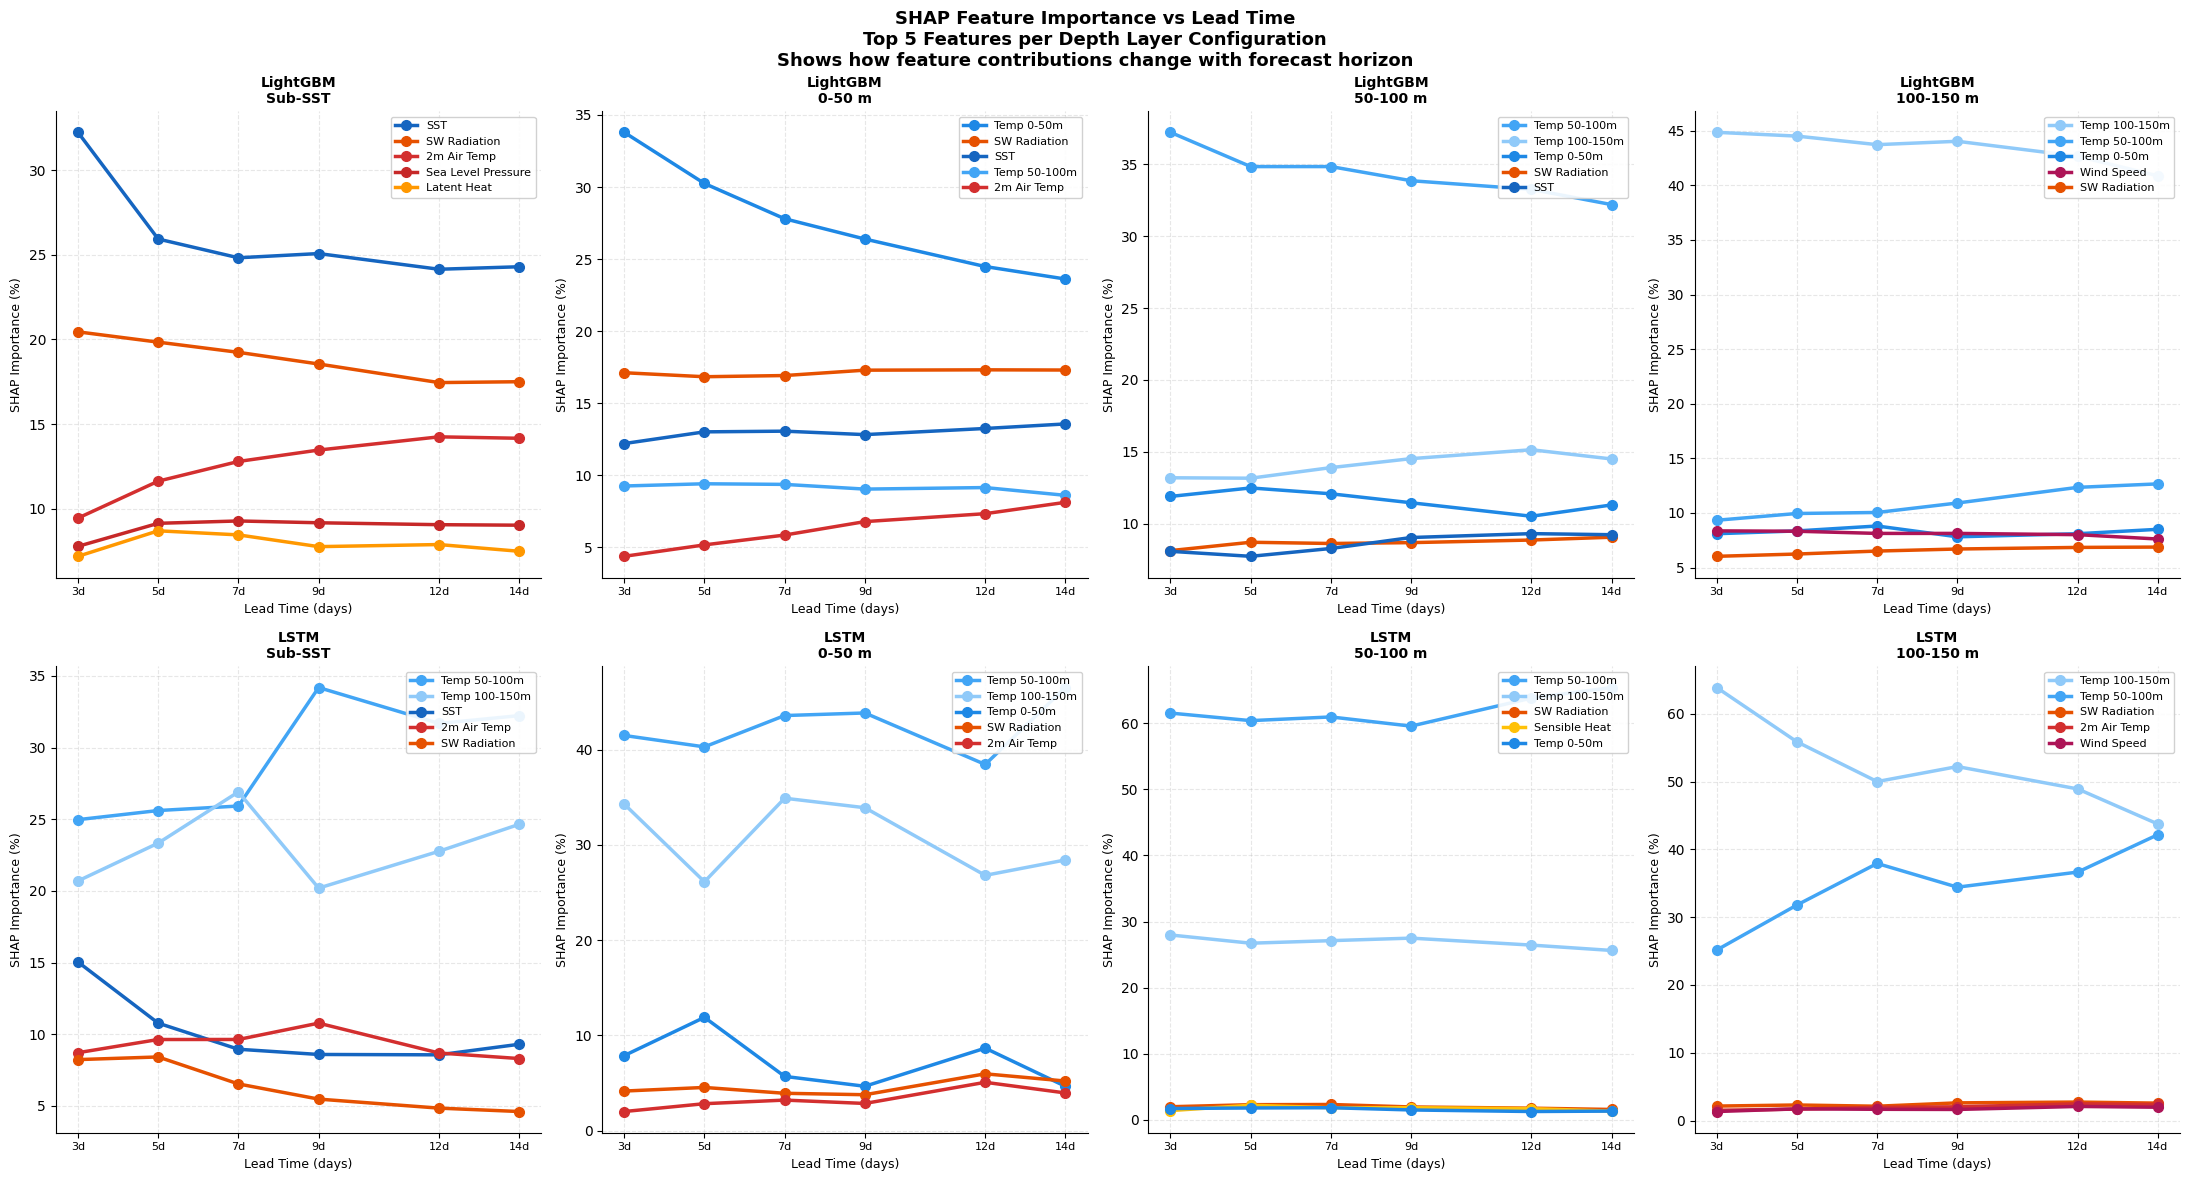

Saved: shap3_vs_lead.png


In [21]:

fig, axes = plt.subplots(2, 4, figsize=(22, 12))
fig.suptitle(
    'SHAP Feature Importance vs Lead Time\n'
    'Top 5 Features per Depth Layer Configuration\n'
    'Shows how feature contributions change with forecast horizon',
    fontsize=13, fontweight='bold'
)

for row, model in enumerate(MODELS):
    for col, config in enumerate(CONFIGS):
        ax = axes[row, col]

        # Get top 5 features by mean importance
        # for this model+config
        top5 = shap_mean[
            (shap_mean['model']  == model) &
            (shap_mean['config'] == config)
        ].nlargest(5, 'shap_importance')[
            'feature'
        ].tolist()

        # Plot one line per top feature
        for feat in top5:
            feat_data = shap_df[
                (shap_df['model']   == model) &
                (shap_df['config']  == config) &
                (shap_df['feature'] == feat)
            ].sort_values('lead_time')

            fl = feat_label(feat)
            ax.plot(
                feat_data['lead_time'],
                feat_data['shap_importance'],
                marker='o',
                linewidth=2.5,
                markersize=7,
                color=FEATURE_COLORS.get(fl, '#666666'),
                label=fl
            )

        ax.set_title(
            f'{model}\n{CONFIG_LABELS[config]}',
            fontsize=10, fontweight='bold'
        )
        ax.set_xlabel('Lead Time (days)', fontsize=9)
        ax.set_ylabel('SHAP Importance (%)', fontsize=9)
        ax.set_xticks(LEAD_TIMES)
        ax.set_xticklabels(
            [f'{l}d' for l in LEAD_TIMES], fontsize=8
        )
        ax.legend(
            fontsize=8, loc='upper right',
            framealpha=0.9
        )
        ax.grid(alpha=0.3, linestyle='--')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(
    EVAL_OUT_DIR /  f'shap3_vs_lead.png',
    dpi=1500, bbox_inches='tight'
)
plt.show()
print('Saved: shap3_vs_lead.png')

### LightGBM vs LSTM — SHAP Feature Importance Comparison


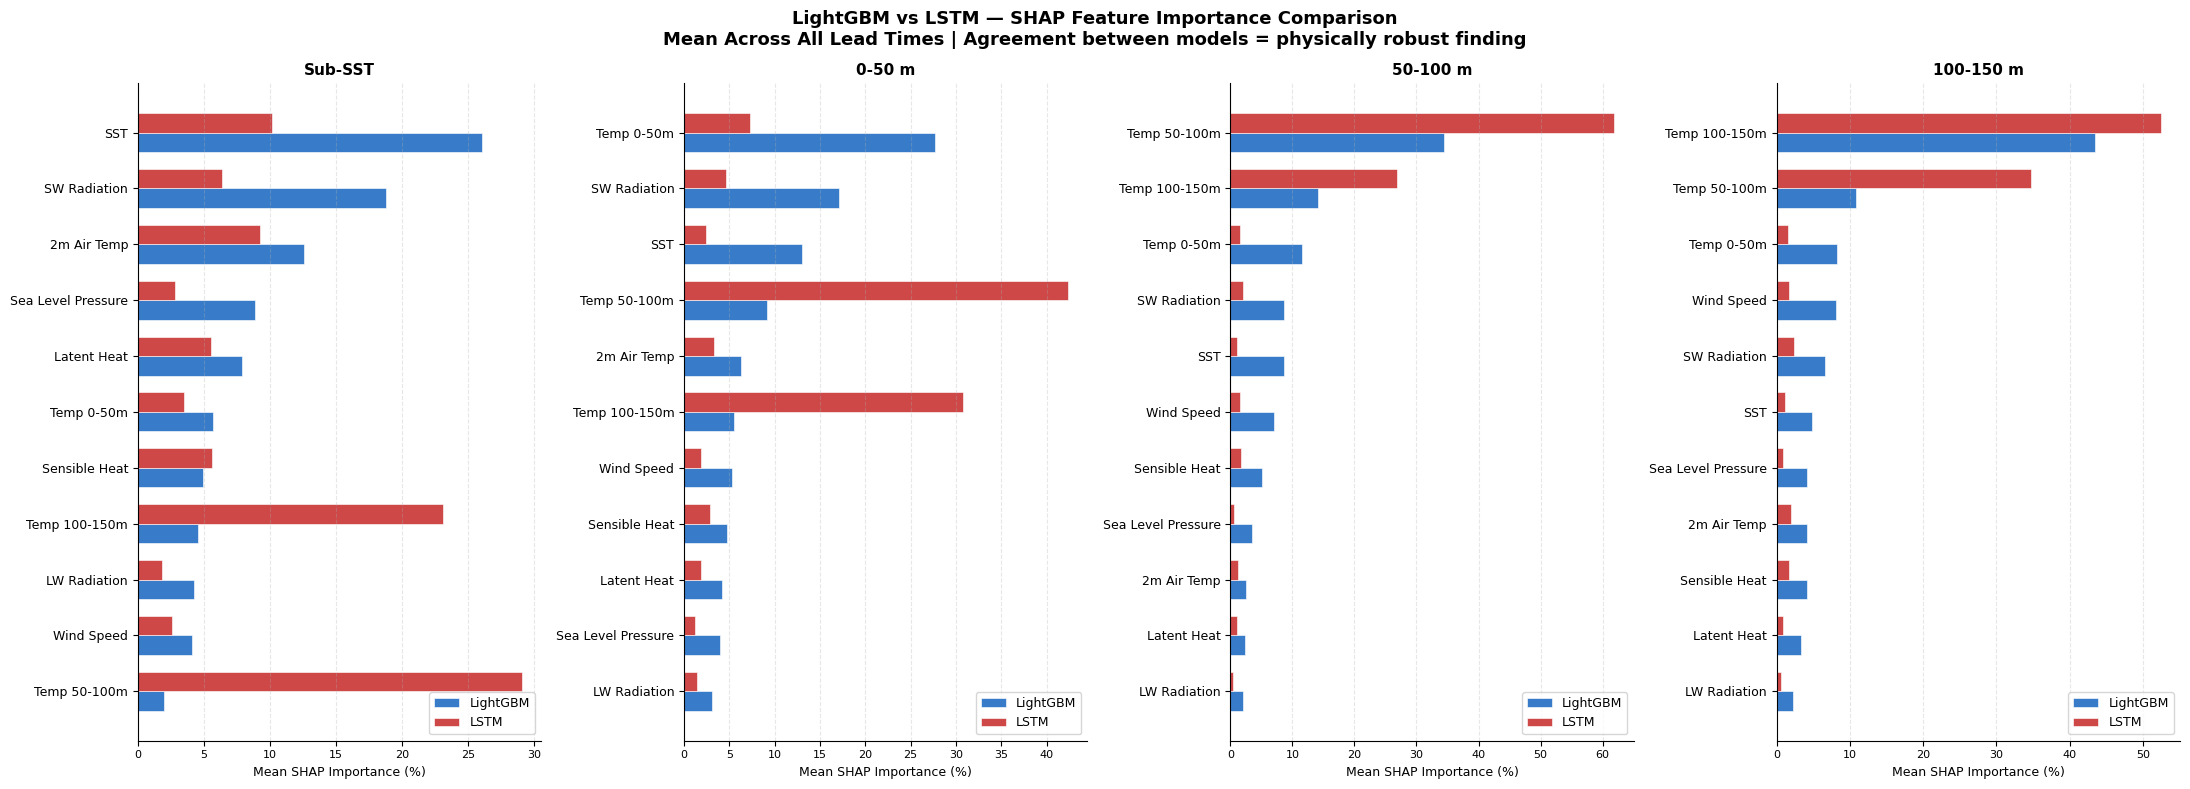

Saved: shap4_lgbm_vs_lstm.png


In [22]:

fig, axes = plt.subplots(1, 4, figsize=(22, 8))
fig.suptitle(
    'LightGBM vs LSTM — SHAP Feature Importance Comparison\n'
    'Mean Across All Lead Times | '
    'Agreement between models = physically robust finding',
    fontsize=13, fontweight='bold'
)

width = 0.35

for col, config in enumerate(CONFIGS):
    ax = axes[col]

    # Get all features for this config
    all_feats = shap_mean[
        shap_mean['config'] == config
    ]['feature'].unique()

    # Mean importance per model
    lgbm_imp = shap_mean[
        (shap_mean['model']  == 'LightGBM') &
        (shap_mean['config'] == config)
    ].set_index('feature')['shap_importance']

    lstm_imp = shap_mean[
        (shap_mean['model']  == 'LSTM') &
        (shap_mean['config'] == config)
    ].set_index('feature')['shap_importance']

    # Align features — sort by LightGBM importance
    lgbm_sorted = lgbm_imp.sort_values(ascending=True)
    feats_ordered = lgbm_sorted.index.tolist()
    feat_labels_ordered = [
        feat_label(f) for f in feats_ordered
    ]

    lgbm_vals = lgbm_sorted.values
    lstm_vals = lstm_imp.reindex(
        feats_ordered, fill_value=0
    ).values

    y = np.arange(len(feats_ordered))

    # LightGBM bars — left
    ax.barh(
        y - width/2, lgbm_vals, width,
        label='LightGBM',
        color=C['LightGBM'],
        alpha=0.85,
        edgecolor='white',
        linewidth=0.5
    )
    # LSTM bars — right
    ax.barh(
        y + width/2, lstm_vals, width,
        label='LSTM',
        color=C['LSTM'],
        alpha=0.85,
        edgecolor='white',
        linewidth=0.5
    )

    ax.set_yticks(y)
    ax.set_yticklabels(feat_labels_ordered, fontsize=9)
    ax.set_title(
        CONFIG_LABELS[config],
        fontsize=11, fontweight='bold'
    )
    ax.set_xlabel('Mean SHAP Importance (%)', fontsize=9)
    ax.legend(fontsize=9, loc='lower right')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    ax.tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.savefig(
    EVAL_OUT_DIR / f'shap4_lgbm_vs_lstm.png',
    dpi=1500, bbox_inches='tight'
)
plt.show()
print('Saved: shap4_lgbm_vs_lstm.png')

### Atmospheric vs Ocean Feature Contribution

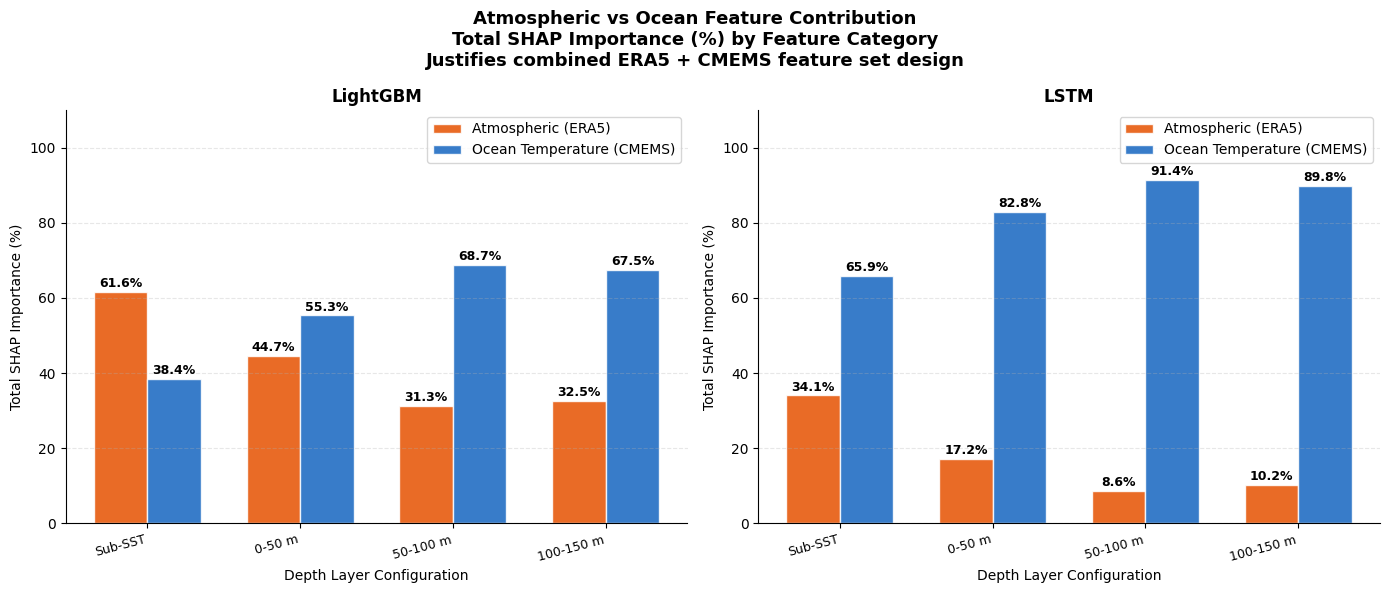

Saved: shap5_atmos_vs_ocean.png


In [23]:


# Define feature categories
ATMOS_FEATURES = {
    'ssr_flux', 'str_flux', 'latent_flux',
    'sensible_flux', 't2m', 'msl', 'wind_speed'
}
OCEAN_FEATURES = {
    'sst', 'temp_0_50m', 'temp_50_100m', 'temp_100_150m'
}

# Compute total atmospheric vs ocean SHAP per model+config
cat_rows = []
for model in MODELS:
    for config in CONFIGS:
        sub = shap_mean[
            (shap_mean['model']  == model) &
            (shap_mean['config'] == config)
        ]
        atmos_total = sub[
            sub['feature'].isin(ATMOS_FEATURES)
        ]['shap_importance'].sum()
        ocean_total = sub[
            sub['feature'].isin(OCEAN_FEATURES)
        ]['shap_importance'].sum()
        cat_rows.append({
            'model':  model,
            'config': config,
            'Atmospheric': atmos_total,
            'Ocean':        ocean_total,
        })

cat_df = pd.DataFrame(cat_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'Atmospheric vs Ocean Feature Contribution\n'
    'Total SHAP Importance (%) by Feature Category\n'
    'Justifies combined ERA5 + CMEMS feature set design',
    fontsize=13, fontweight='bold'
)

x     = np.arange(len(CONFIGS))
width = 0.35

for ax, model in zip(axes, MODELS):
    sub = cat_df[cat_df['model'] == model]

    atmos_vals = sub['Atmospheric'].values
    ocean_vals = sub['Ocean'].values

    bars_a = ax.bar(
        x - width/2, atmos_vals, width,
        label='Atmospheric (ERA5)',
        color='#E65100', alpha=0.85,
        edgecolor='white'
    )
    bars_o = ax.bar(
        x + width/2, ocean_vals, width,
        label='Ocean Temperature (CMEMS)',
        color='#1565C0', alpha=0.85,
        edgecolor='white'
    )

    # Value labels
    for bar in list(bars_a) + list(bars_o):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 0.5,
            f'{h:.1f}%',
            ha='center', va='bottom',
            fontsize=9, fontweight='bold'
        )

    ax.set_title(
        model, fontsize=12, fontweight='bold'
    )
    ax.set_xlabel(
        'Depth Layer Configuration', fontsize=10
    )
    ax.set_ylabel(
        'Total SHAP Importance (%)', fontsize=10
    )
    ax.set_xticks(x)
    ax.set_xticklabels(
        [CONFIG_LABELS[c] for c in CONFIGS],
        rotation=15, ha='right', fontsize=9
    )
    ax.set_ylim(0, 110)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(
    EVAL_OUT_DIR / f'shap5_atmos_vs_ocean.png',
    dpi=1500, bbox_inches='tight'
)
plt.show()
print('Saved: shap5_atmos_vs_ocean.png')

## Each Model Feature Importance

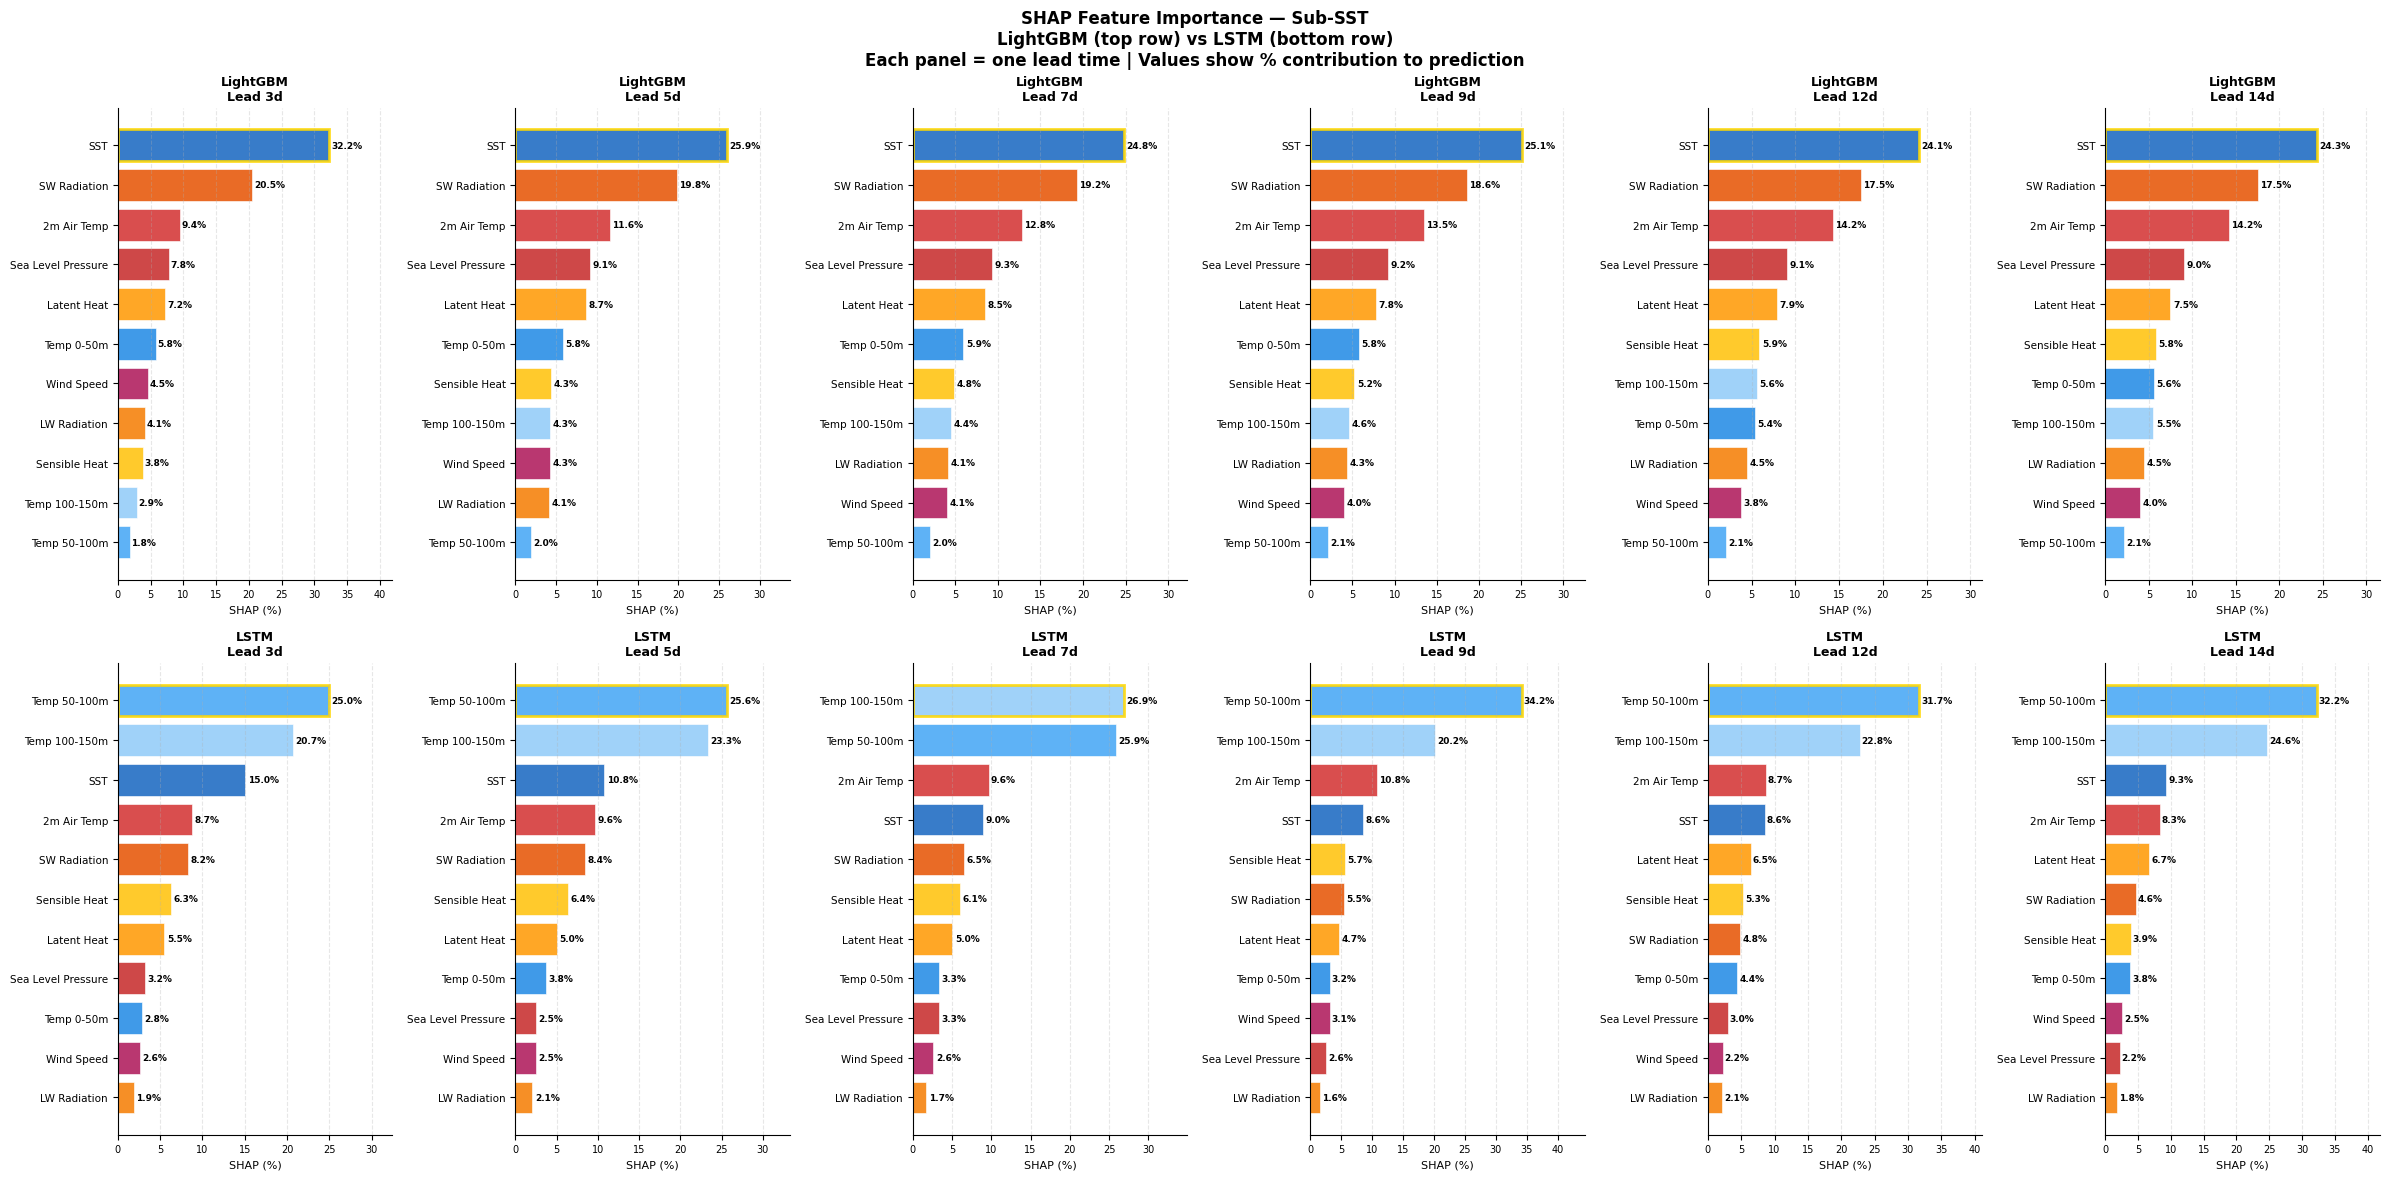

Saved: shap_detail_SubSST.png


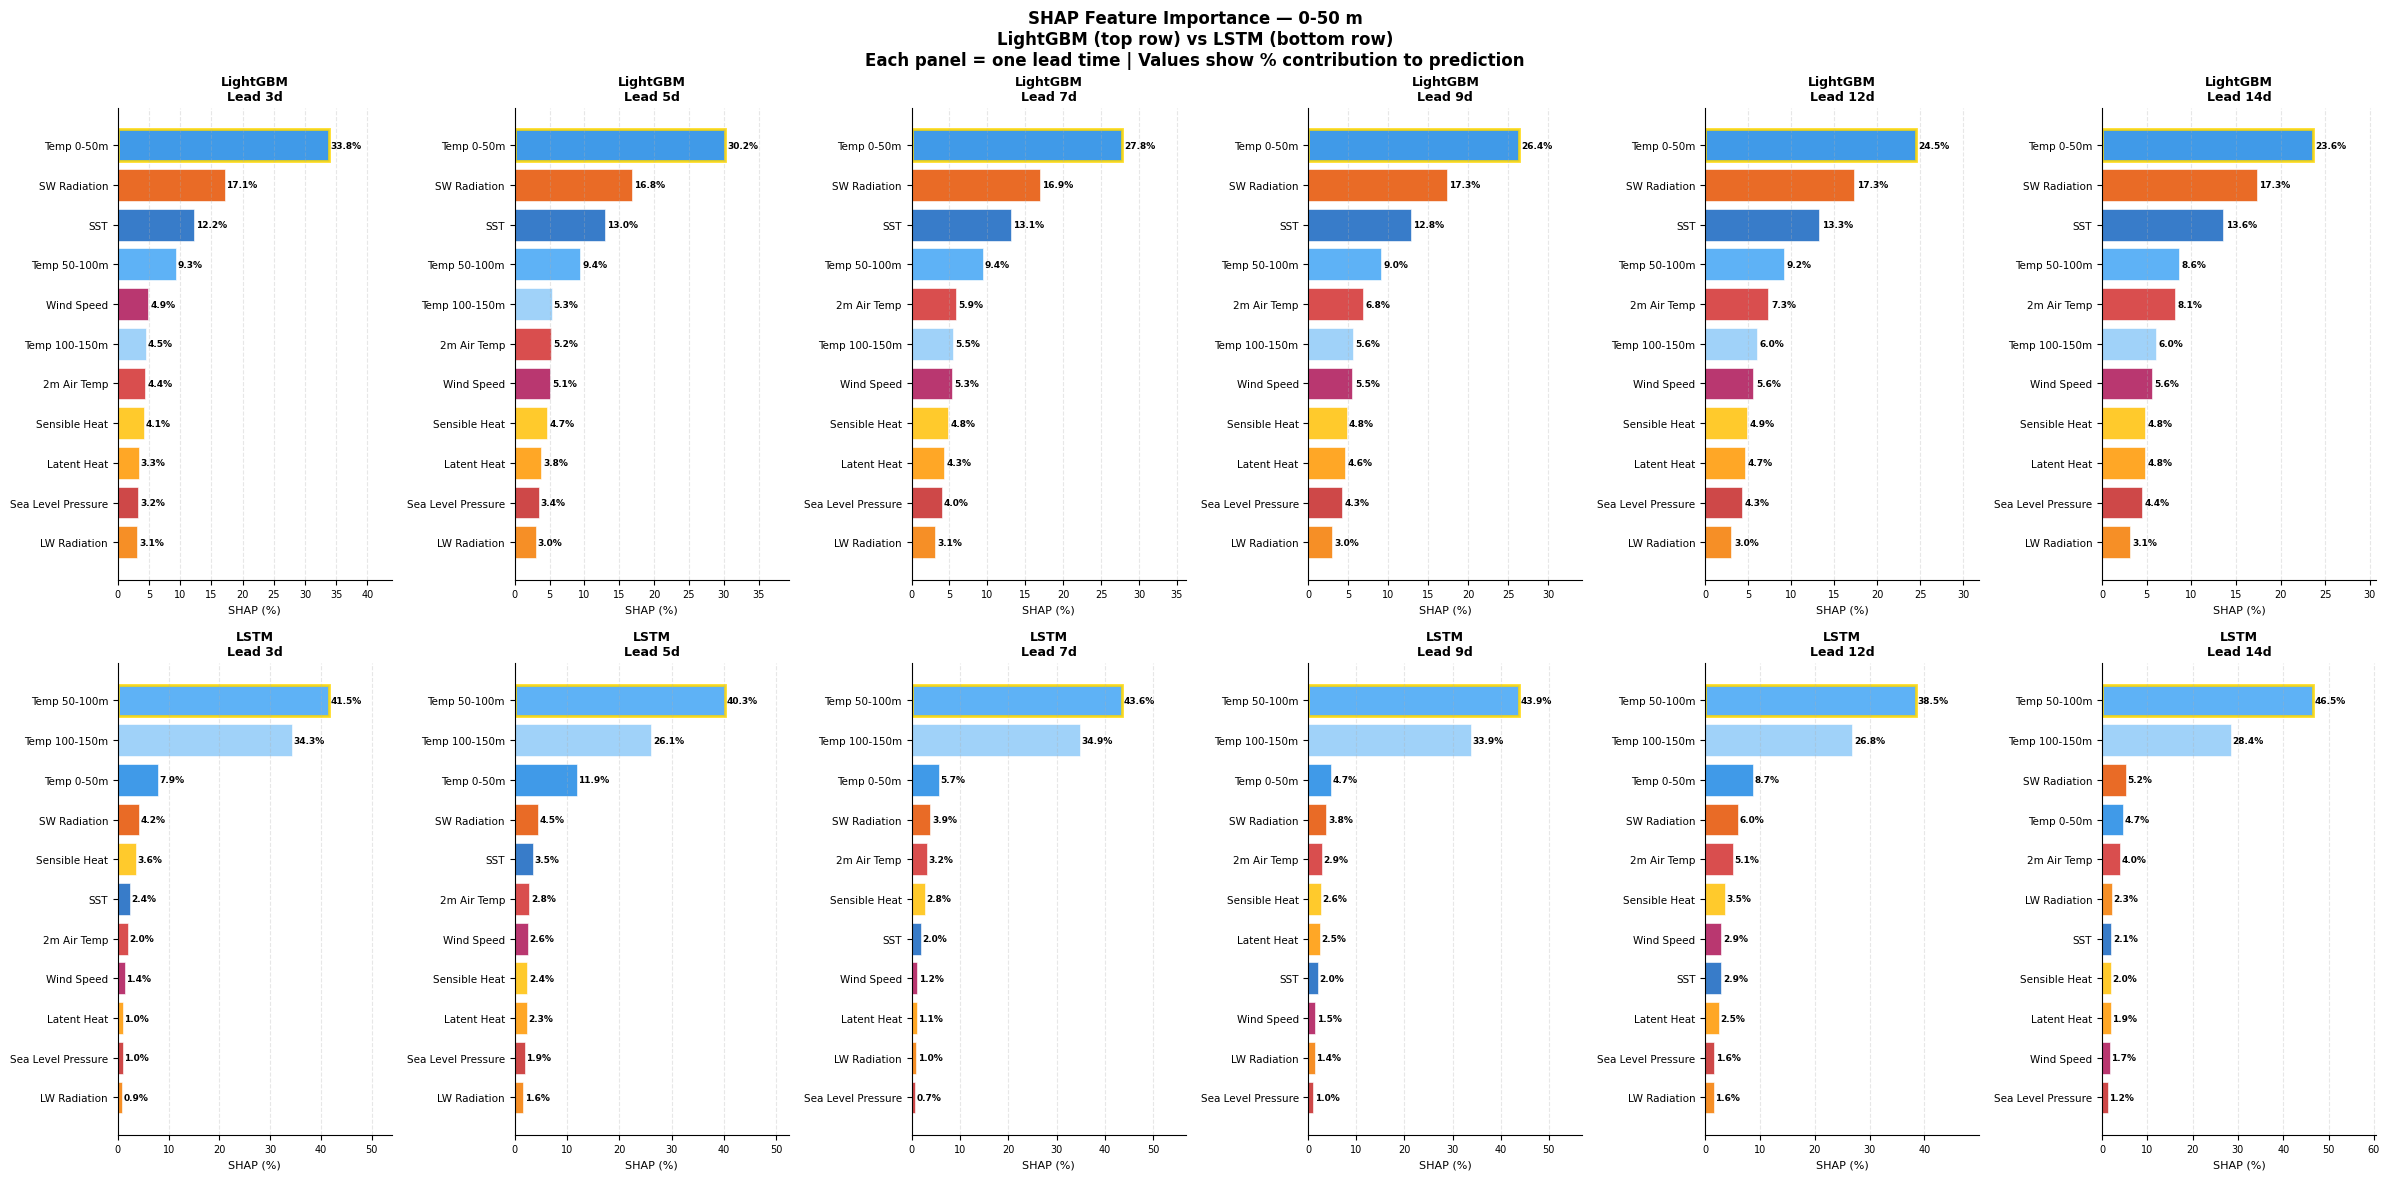

Saved: shap_detail_050m.png


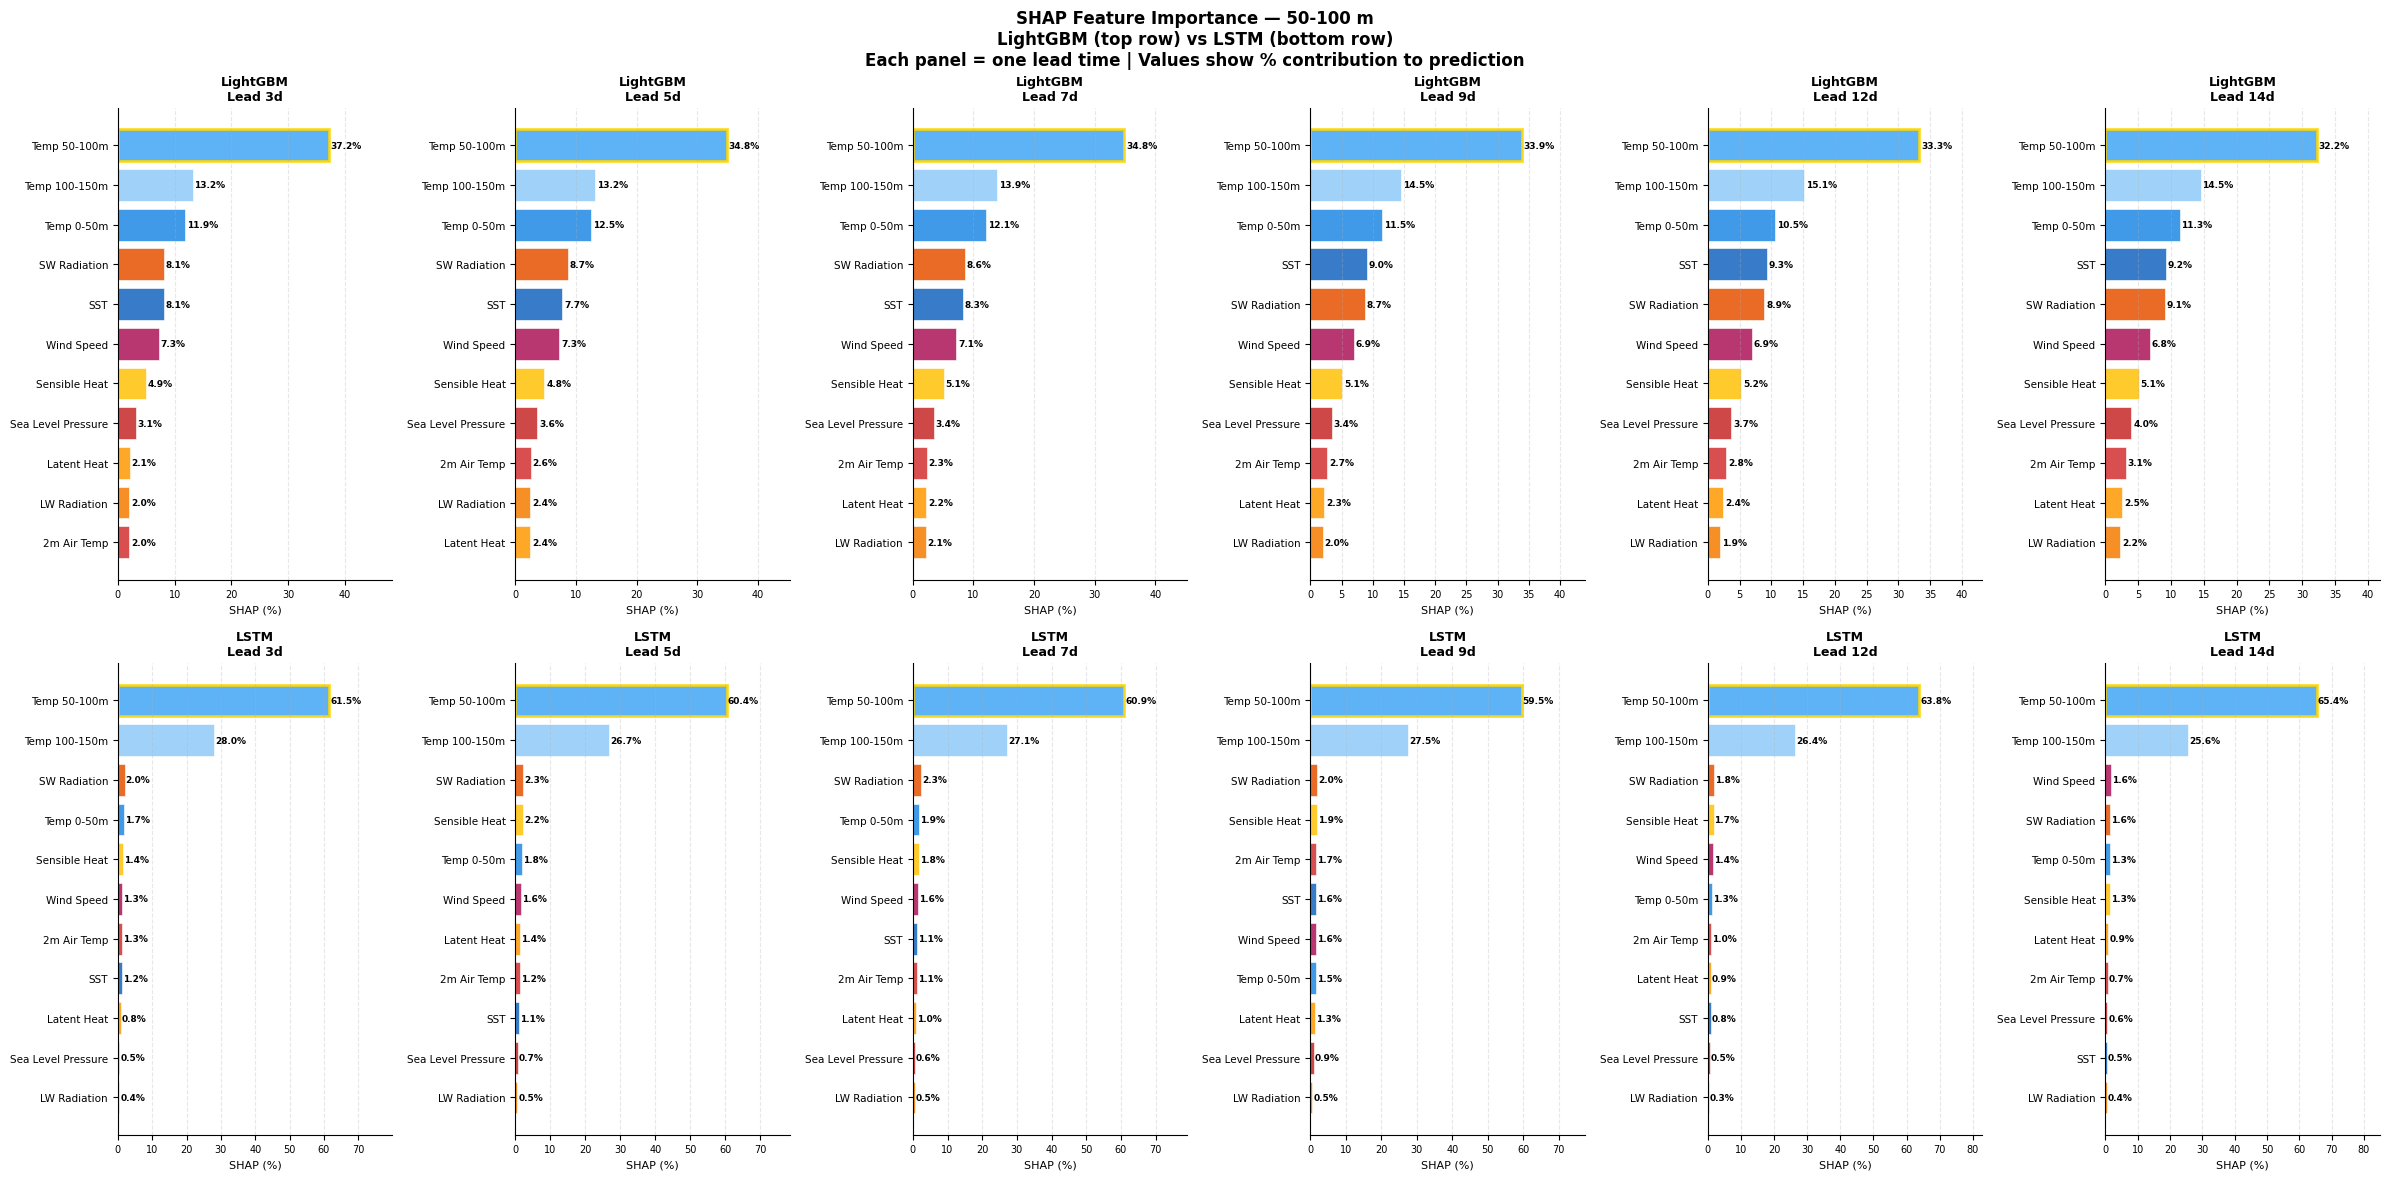

Saved: shap_detail_50100m.png


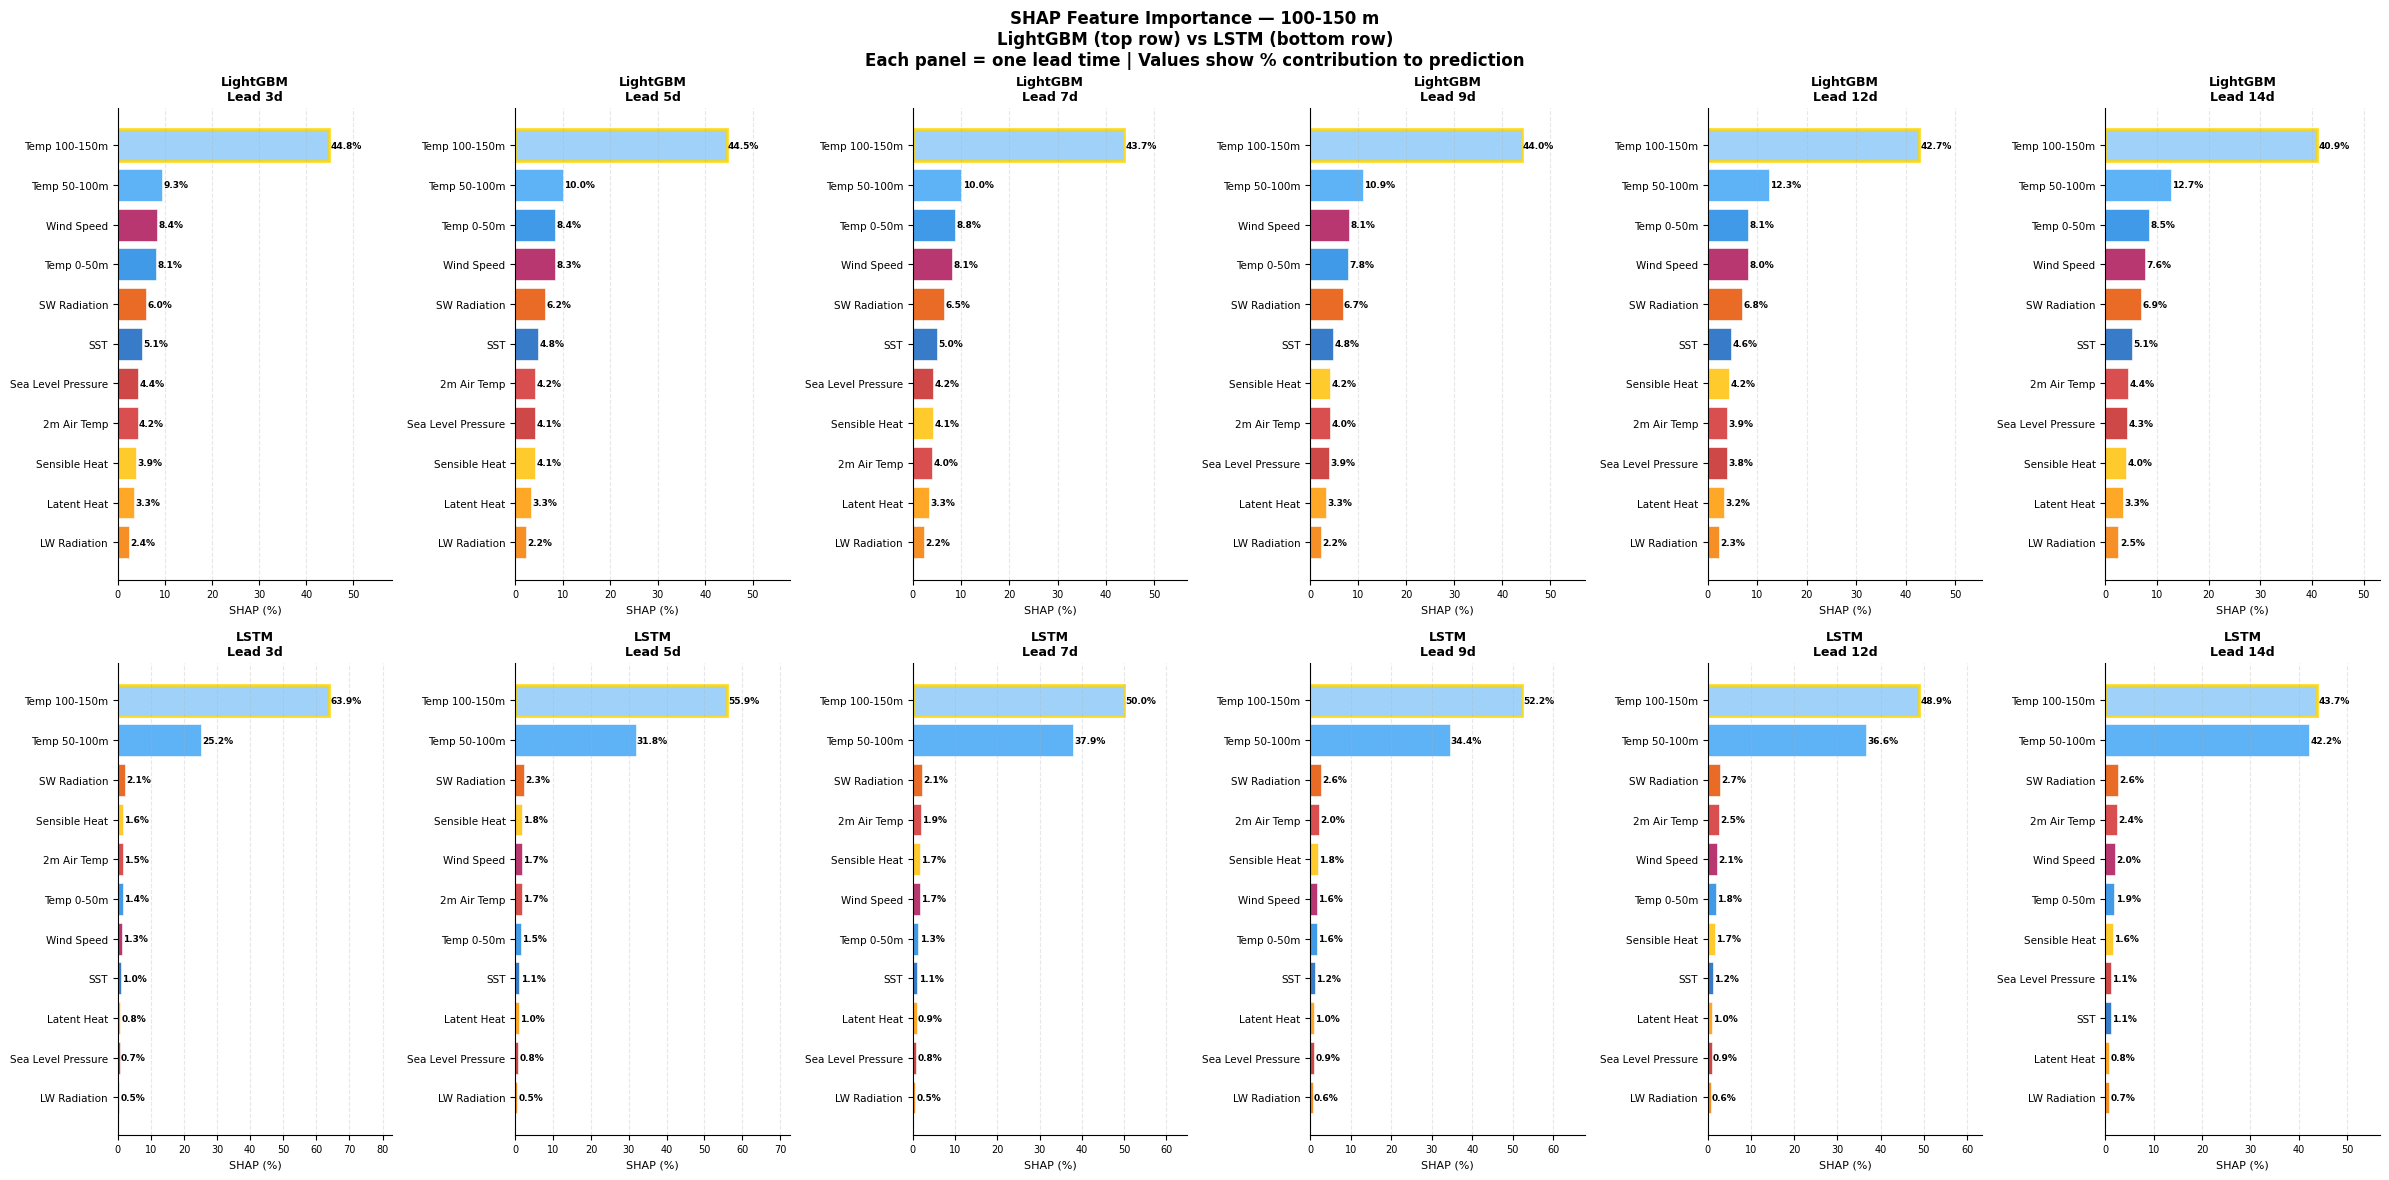

Saved: shap_detail_100150m.png

All per-config SHAP plots saved:


In [24]:


for config in CONFIGS:

    fig, axes = plt.subplots(
        2, len(LEAD_TIMES),
        figsize=(24, 12)
    )
    fig.suptitle(
        f'SHAP Feature Importance — {CONFIG_LABELS[config]}\n'
        f'LightGBM (top row) vs LSTM (bottom row)\n'
        f'Each panel = one lead time | '
        f'Values show % contribution to prediction',
        fontsize=12, fontweight='bold'
    )

    for row, model in enumerate(MODELS):
        for col, lead in enumerate(LEAD_TIMES):
            ax = axes[row, col]

            # Get SHAP for this model+config+lead
            # sorted ascending so top feature at top
            sub = shap_df[
                (shap_df['model']     == model) &
                (shap_df['config']    == config) &
                (shap_df['lead_time'] == lead)
            ].sort_values(
                'shap_importance', ascending=True
            )

            if len(sub) == 0:
                ax.set_visible(False)
                continue

            # Feature display names
            feat_labels_list = [
                feat_label(f) for f in sub['feature']
            ]

            # Bar colours by feature category
            bar_colors = [
                FEATURE_COLORS.get(fl, '#666666')
                for fl in feat_labels_list
            ]

            bars = ax.barh(
                feat_labels_list,
                sub['shap_importance'].values,
                color=bar_colors,
                alpha=0.85,
                edgecolor='white',
                linewidth=0.5
            )

            # Value labels
            for bar in bars:
                w = bar.get_width()
                ax.text(
                    w + 0.3,
                    bar.get_y() + bar.get_height()/2,
                    f'{w:.1f}%',
                    va='center',
                    fontsize=6.5,
                    fontweight='bold'
                )

            # Title shows model + lead time
            ax.set_title(
                f'{model}\nLead {lead}d',
                fontsize=9,
                fontweight='bold'
            )
            ax.set_xlabel(
                'SHAP (%)', fontsize=8
            )
            ax.set_xlim(
                0,
                sub['shap_importance'].max() * 1.3
            )
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.tick_params(
                axis='y', labelsize=7.5
            )
            ax.tick_params(
                axis='x', labelsize=7
            )
            ax.grid(
                axis='x', alpha=0.3,
                linestyle='--'
            )

            # Highlight top feature
            bars[-1].set_edgecolor('gold')
            bars[-1].set_linewidth(2.0)

    plt.tight_layout()
    fname = (
        f'shap_detail_'
        f'{config.replace("-","").replace(" ","_")}.png'
    )
    plt.savefig(
        EVAL_OUT_DIR / f'{fname}',
        dpi=1500, bbox_inches='tight'
    )
    plt.show()
    print(f'Saved: {fname}')

print('\nAll per-config SHAP plots saved:')

### Feature Comparison in Multibar Plot

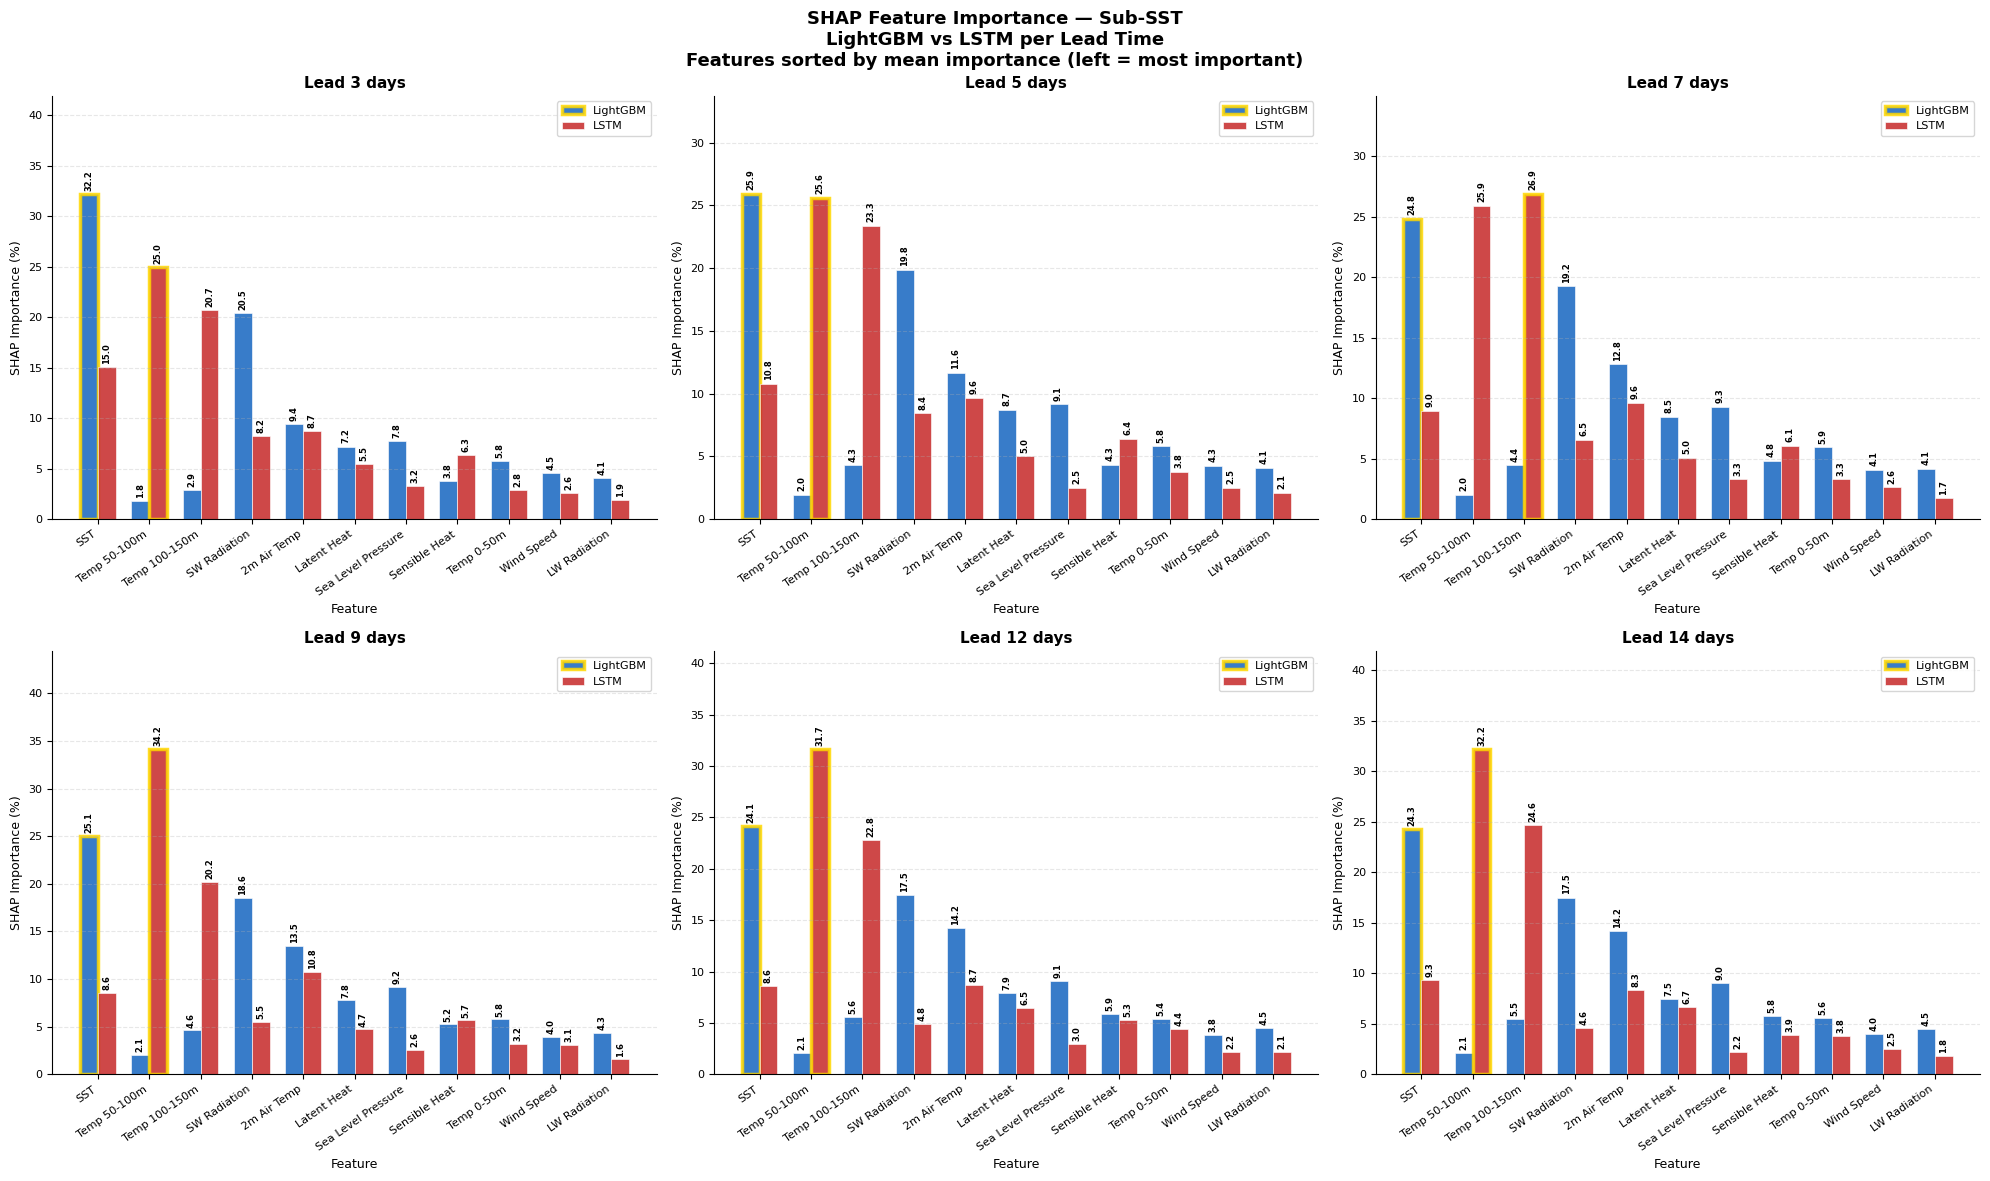

Saved: shap_lgbm_lstm_SubSST.png


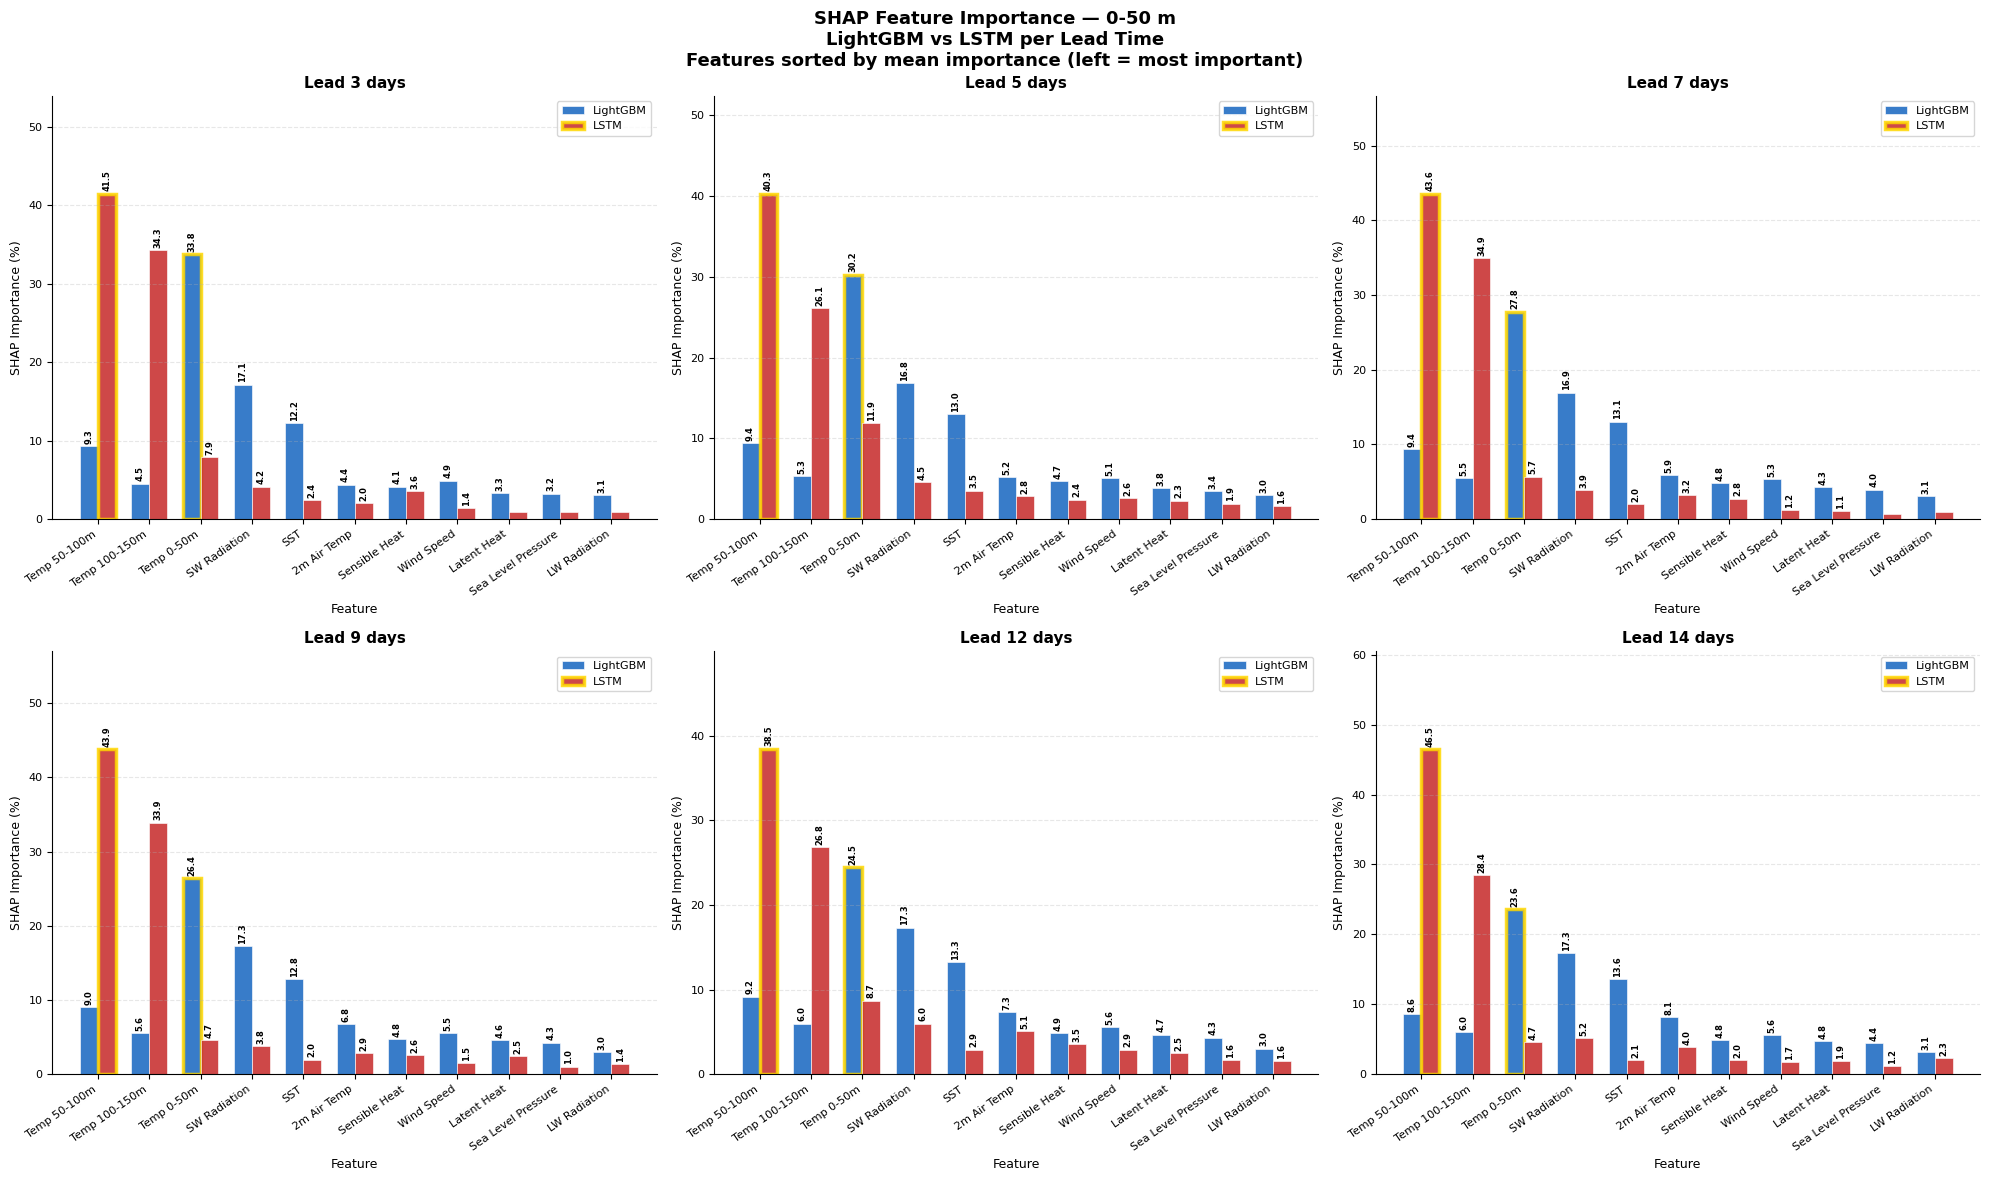

Saved: shap_lgbm_lstm_050m.png


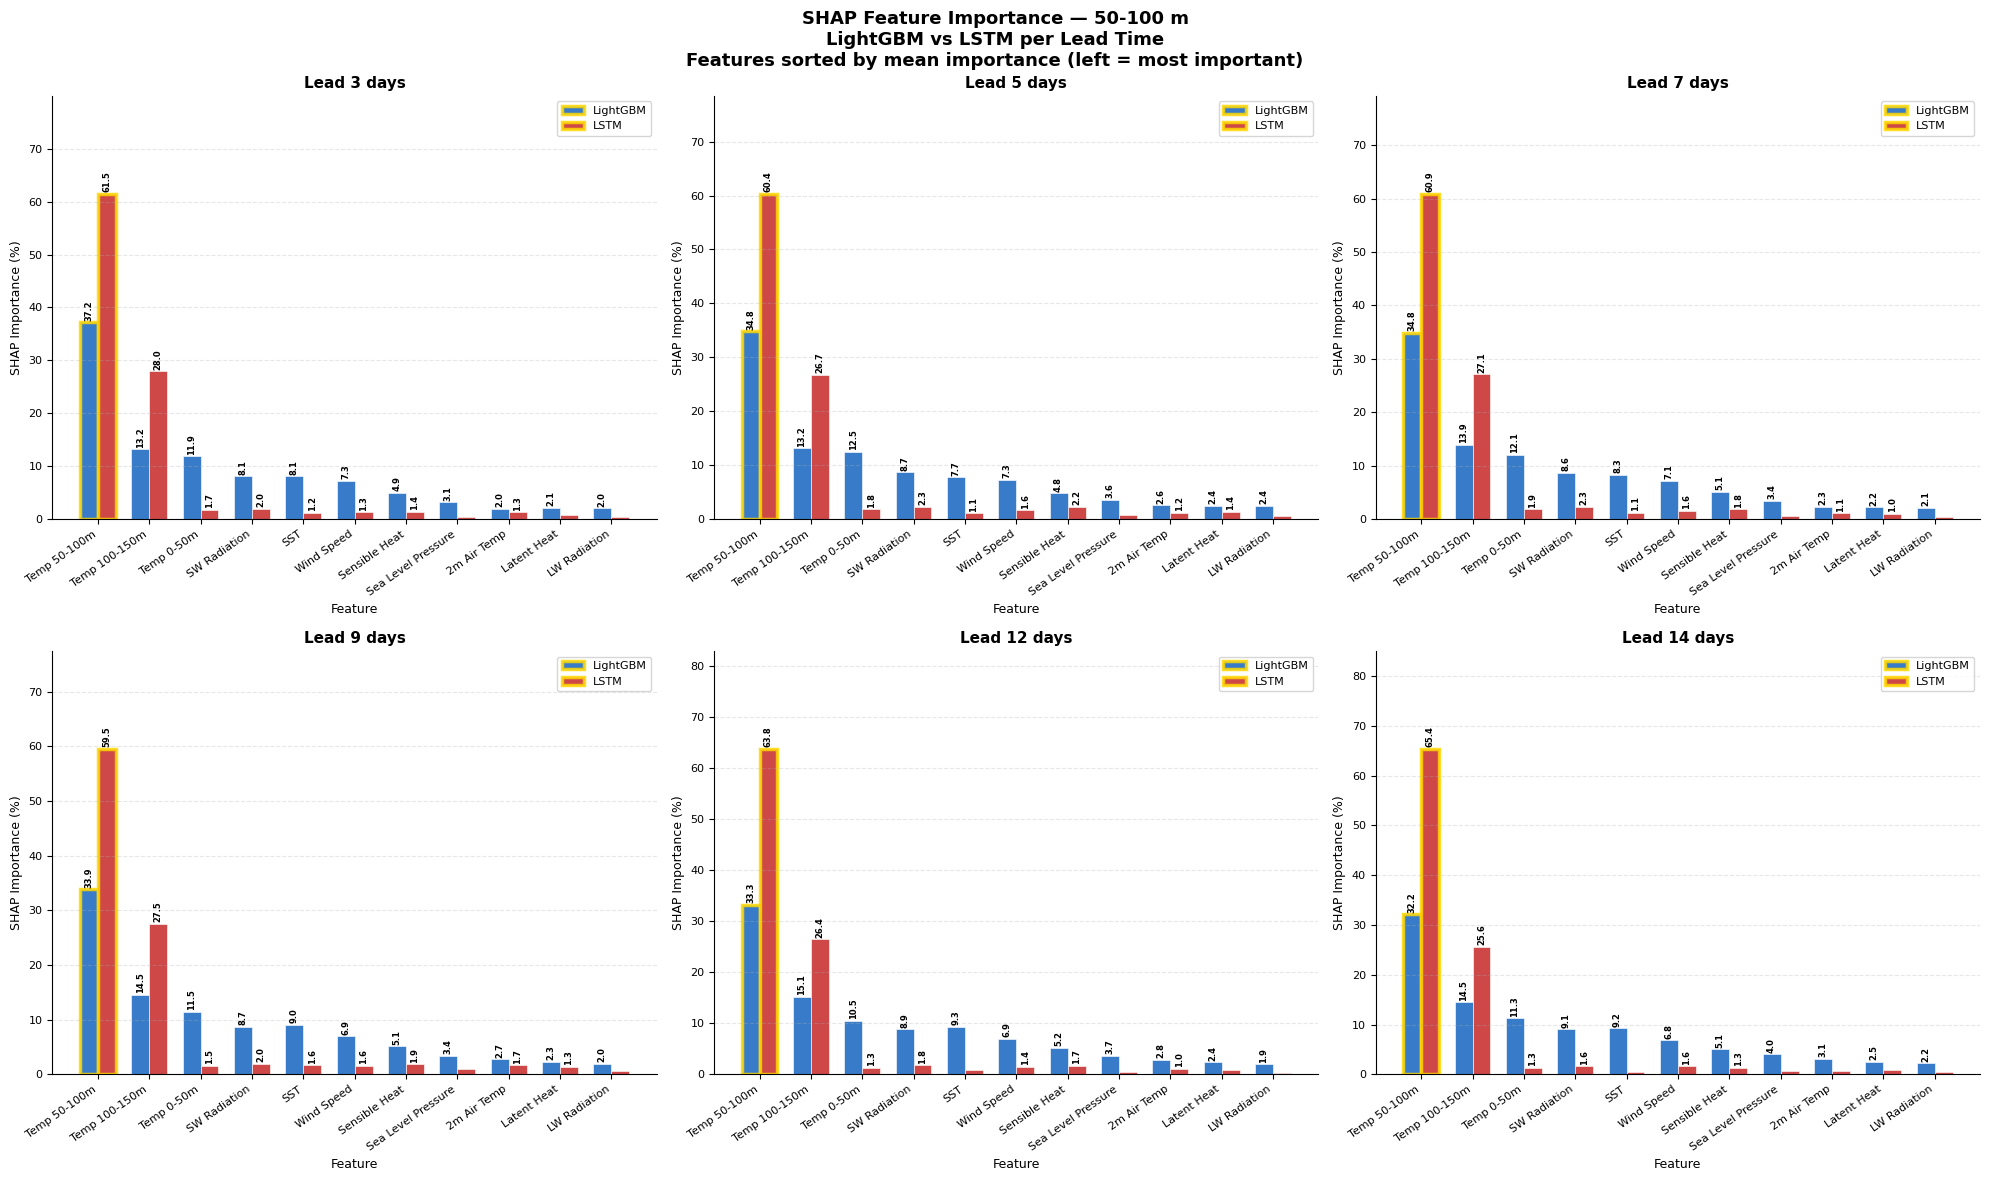

Saved: shap_lgbm_lstm_50100m.png


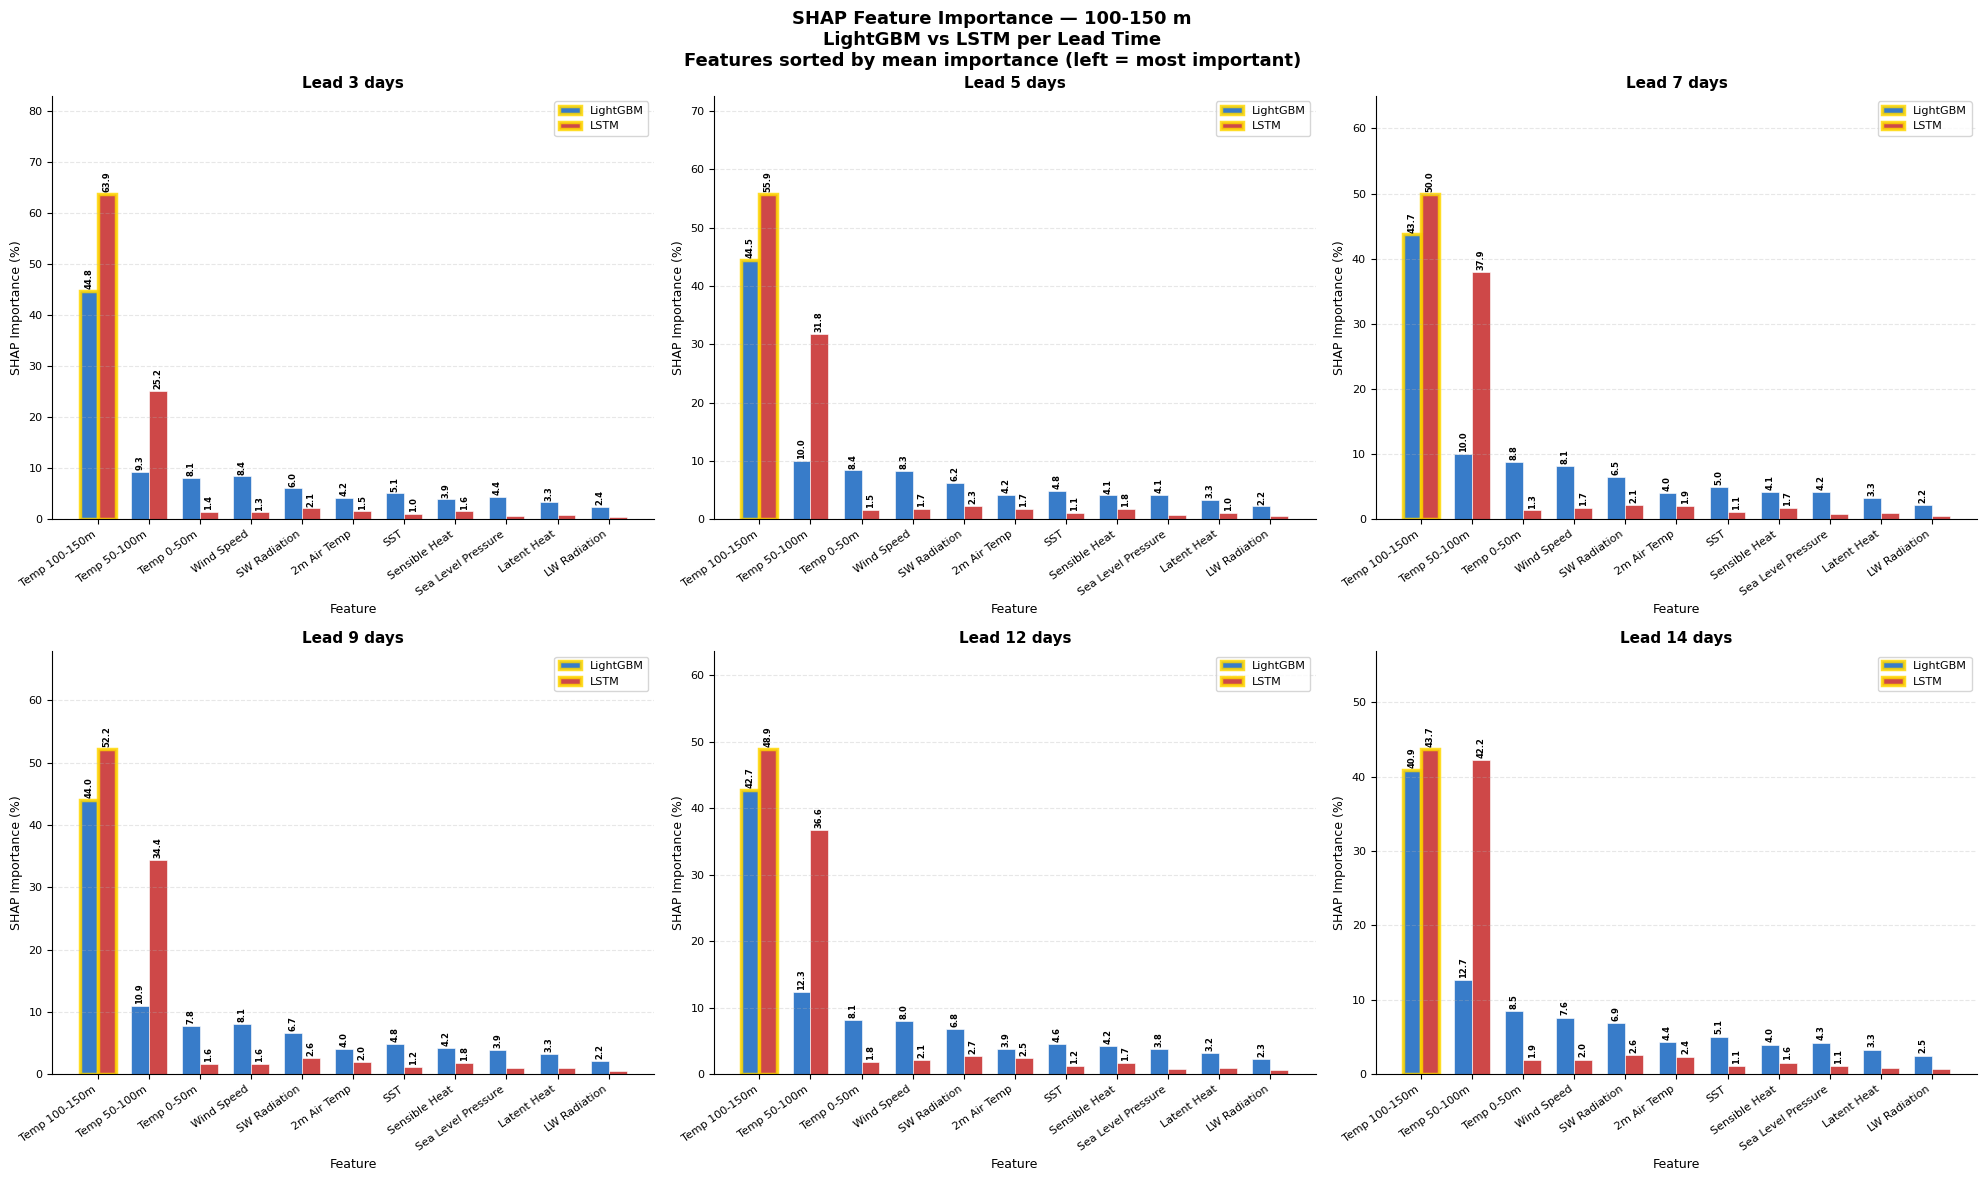

Saved: shap_lgbm_lstm_100150m.png

TOP FEATURE COMPARISON — LightGBM vs LSTM
Gold border in plots marks these features

Sub-SST:
    Lead           LightGBM #1    SHAP%               LSTM #1    SHAP%   Agree?
  ---------------------------------------------------------------------------
       3d                   SST     32.2%          Temp 50-100m     25.0%       No
       5d                   SST     25.9%          Temp 50-100m     25.6%       No
       7d                   SST     24.8%         Temp 100-150m     26.9%       No
       9d                   SST     25.1%          Temp 50-100m     34.2%       No
      12d                   SST     24.1%          Temp 50-100m     31.7%       No
      14d                   SST     24.3%          Temp 50-100m     32.2%       No

0-50 m:
    Lead           LightGBM #1    SHAP%               LSTM #1    SHAP%   Agree?
  ---------------------------------------------------------------------------
       3d            Temp 0-50m     33.8%       

In [25]:

for config in CONFIGS:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(20, 12)
    )
    fig.suptitle(
        f'SHAP Feature Importance — {CONFIG_LABELS[config]}\n'
        f'LightGBM vs LSTM per Lead Time\n'
        f'Features sorted by mean importance (left = most important)',
        fontsize=13, fontweight='bold'
    )
    axes = axes.flatten()

    # Get feature order — sorted by mean importance
    # across both models and all lead times for this config
    # So feature order is consistent across all 6 subplots
    feat_order = shap_df[
        shap_df['config'] == config
    ].groupby('feature')['shap_importance'].mean(
    ).sort_values(ascending=False).index.tolist()

    feat_labels_ordered = [
        feat_label(f) for f in feat_order
    ]

    x     = np.arange(len(feat_order))
    width = 0.35

    for idx, lead in enumerate(LEAD_TIMES):
        ax = axes[idx]

        # LightGBM values for this config+lead
        lgbm_sub = shap_df[
            (shap_df['model']     == 'LightGBM') &
            (shap_df['config']    == config) &
            (shap_df['lead_time'] == lead)
        ].set_index('feature')['shap_importance']

        # LSTM values for this config+lead
        lstm_sub = shap_df[
            (shap_df['model']     == 'LSTM') &
            (shap_df['config']    == config) &
            (shap_df['lead_time'] == lead)
        ].set_index('feature')['shap_importance']

        # Reindex to consistent feature order
        # fill 0 if feature missing
        lgbm_vals = lgbm_sub.reindex(
            feat_order, fill_value=0
        ).values
        lstm_vals = lstm_sub.reindex(
            feat_order, fill_value=0
        ).values

        # LightGBM bars — left of centre
        bars_lgbm = ax.bar(
            x - width/2,
            lgbm_vals,
            width,
            label='LightGBM',
            color=C['LightGBM'],
            alpha=0.85,
            edgecolor='white',
            linewidth=0.5
        )

        # LSTM bars — right of centre
        bars_lstm = ax.bar(
            x + width/2,
            lstm_vals,
            width,
            label='LSTM',
            color=C['LSTM'],
            alpha=0.85,
            edgecolor='white',
            linewidth=0.5
        )

        # Value labels on top of each bar
        for bar in list(bars_lgbm) + list(bars_lstm):
            h = bar.get_height()
            if h > 1.0:  # only label bars > 1%
                ax.text(
                    bar.get_x() + bar.get_width()/2,
                    h + 0.3,
                    f'{h:.1f}',
                    ha='center',
                    va='bottom',
                    fontsize=6,
                    fontweight='bold',
                    rotation=90
                )

        # Highlight top feature for LightGBM
        # gold border on tallest LightGBM bar
        top_lgbm_idx = np.argmax(lgbm_vals)
        bars_lgbm[top_lgbm_idx].set_edgecolor('gold')
        bars_lgbm[top_lgbm_idx].set_linewidth(2.5)

        # Highlight top feature for LSTM
        top_lstm_idx = np.argmax(lstm_vals)
        bars_lstm[top_lstm_idx].set_edgecolor('gold')
        bars_lstm[top_lstm_idx].set_linewidth(2.5)

        ax.set_title(
            f'Lead {lead} days',
            fontsize=11, fontweight='bold'
        )
        ax.set_xlabel('Feature', fontsize=9)
        ax.set_ylabel(
            'SHAP Importance (%)', fontsize=9
        )
        ax.set_xticks(x)
        ax.set_xticklabels(
            feat_labels_ordered,
            rotation=35,
            ha='right',
            fontsize=8
        )
        ax.tick_params(axis='y', labelsize=8)
        ax.set_ylim(
            0,
            max(lgbm_vals.max(),
                lstm_vals.max()) * 1.3
        )
        ax.legend(fontsize=8, loc='upper right')
        ax.grid(
            axis='y', alpha=0.3,
            linestyle='--'
        )
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plt.tight_layout()
    fname = (
        f'shap_lgbm_lstm_'
        f'{config.replace("-","").replace(" ","_")}'
        f'.png'
    )
    plt.savefig(
        EVAL_OUT_DIR / f'{fname}',
        dpi=1500, bbox_inches='tight'
    )
    plt.show()
    print(f'Saved: {fname}')

# Top feature comparison table
print('\n' + '='*80)
print('TOP FEATURE COMPARISON — LightGBM vs LSTM')
print('Gold border in plots marks these features')
print('='*80)

for config in CONFIGS:
    print(f'\n{CONFIG_LABELS[config]}:')
    print(
        f'  {"Lead":>6}  '
        f'{"LightGBM #1":>20}  '
        f'{"SHAP%":>7}  '
        f'{"LSTM #1":>20}  '
        f'{"SHAP%":>7}  '
        f'{"Agree?":>7}'
    )
    print(f'  {"-"*75}')

    for lead in LEAD_TIMES:
        lgbm_top = shap_df[
            (shap_df['model']     == 'LightGBM') &
            (shap_df['config']    == config) &
            (shap_df['lead_time'] == lead) &
            (shap_df['rank']      == 1)
        ]
        lstm_top = shap_df[
            (shap_df['model']     == 'LSTM') &
            (shap_df['config']    == config) &
            (shap_df['lead_time'] == lead) &
            (shap_df['rank']      == 1)
        ]

        if len(lgbm_top) == 0 or len(lstm_top) == 0:
            continue

        lg_feat = feat_label(
            lgbm_top.iloc[0]['feature']
        )
        lg_val  = lgbm_top.iloc[0]['shap_importance']
        ls_feat = feat_label(
            lstm_top.iloc[0]['feature']
        )
        ls_val  = lstm_top.iloc[0]['shap_importance']
        agree   = 'Yes' if lg_feat == ls_feat \
                  else 'No'

        print(
            f'  {lead:>6}d  '
            f'{lg_feat:>20}  '
            f'{lg_val:>7.1f}%  '
            f'{ls_feat:>20}  '
            f'{ls_val:>7.1f}%  '
            f'{agree:>7}'
        )

print('\n' + '='*80)
print('Saved:')
for config in CONFIGS:
    fname = (
        f'shap_lgbm_lstm_'
        f'{config.replace("-","").replace(" ","_")}'
        f'.png'
    )
    print(f'  {fname}')
print('='*80)